# GAN Generation and Latent Space Exploration

MNIST digit generation with a convolutional GAN, plus latent interpolation and vector arithmetic using MNIST and pretrained CelebA generators.


## Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torchvision.utils as vutils
import matplotlib.pyplot as plt
import numpy as np
device = torch.device('cuda' if torch.cuda.is_available() else "cpu")


## MNIST data

Load the standard training and test splits, use batches of 128, and visualize training examples.

100%|██████████| 9.91M/9.91M [00:00<00:00, 13.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 467kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.40MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.10MB/s]


Training size: 60000, Test size: 10000
Train ratio: 85.71%, Test ratio: 14.29%


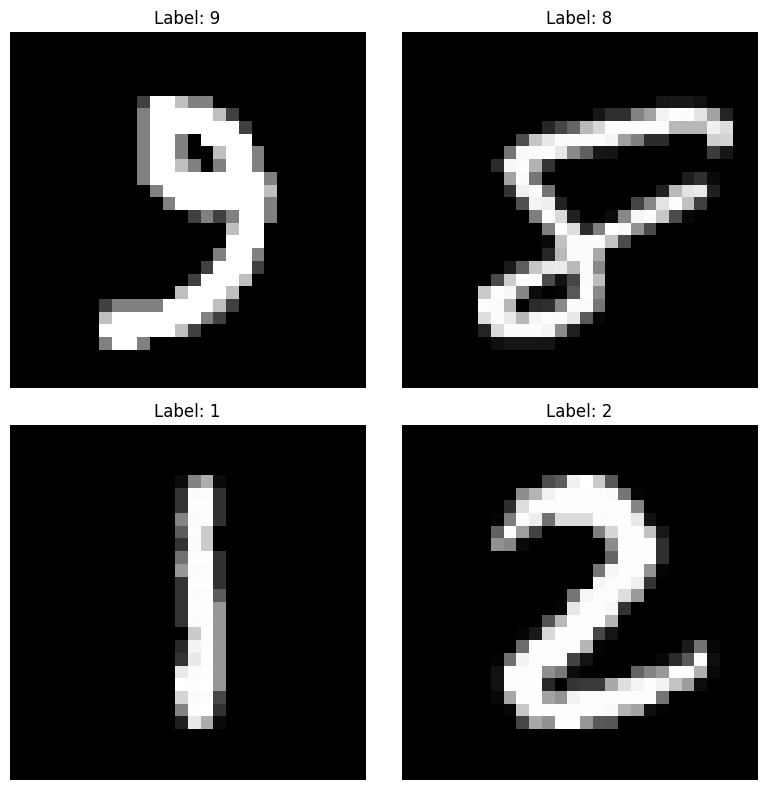

In [2]:
minst_train = datasets.MNIST(root = './data', train = True, download = True, transform = transforms.ToTensor())
minst_test = datasets.MNIST(root = './data', train = False, download = True, transform = transforms.ToTensor())
train_size = len(minst_train)
test_size = len(minst_test)
total_size = train_size + test_size
train_ratio = train_size / total_size
test_ratio = test_size / total_size

print(f"Training size: {train_size}, Test size: {test_size}")
print(f"Train ratio: {train_ratio*100:.2f}%, Test ratio: {test_ratio*100:.2f}%")

train_loader = DataLoader(minst_train, batch_size = 128, shuffle = True)
test_loader = DataLoader(minst_test, batch_size = 128, shuffle = False)

indices = np.random.choice(len(minst_train), 5, replace=False)
images, labels = [], []
for i in indices:
    img, label = minst_train[i]
    images.append(img.squeeze(0))
    labels.append(label)

grid_size = int(np.sqrt(5))
fig, axes = plt.subplots(grid_size, grid_size, figsize=(8,8))
for i in range(grid_size):
    for j in range(grid_size):
        index = i * grid_size + j
        axes[i, j].imshow(images[index], cmap='gray')
        axes[i, j].set_title(f"Label: {labels[index]}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()


## Generator

Map a 50-dimensional noise vector to a 28 × 28 grayscale image using a dense projection, transposed convolutions, batch normalization, and a sigmoid output.

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=50, out_channels=1):
        super(Generator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(latent_dim, 256 * 7 * 7),
            nn.BatchNorm1d(256 * 7 * 7),
            nn.ReLU(inplace=True)
        )
        self.decon = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, out_channels, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.fc(x)
        x = x.view(-1, 256, 7, 7)
        x = self.decon(x)
        return x


## Discriminator

Classify images with strided convolutions, LeakyReLU activations, batch normalization, and a sigmoid output.

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.conv(x)
        x = self.fc(x)
        return x


## Model initialization

In [22]:
generator = Generator()
discriminator = Discriminator()


## Optimization

Use Adam with a learning rate of 0.0002 for both networks. The discriminator uses binary cross-entropy; the generator uses a non-saturating adversarial objective.

In [23]:
criterion = nn.BCELoss()

optimizer_g = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002)


## Training

Alternate discriminator and generator updates for 50 epochs. Real examples use a smoothed target of 0.9. Record epoch losses and display generated samples throughout training.

Epoch [1/50], Batch [0/469], D Loss: 1.1520, G Loss: 2.4553
Epoch [1/50], Batch [100/469], D Loss: 0.3311, G Loss: 7.2907
Epoch [1/50], Batch [200/469], D Loss: 0.3881, G Loss: 4.1422
Epoch [1/50], Batch [300/469], D Loss: 0.5642, G Loss: 2.8923
Epoch [1/50], Batch [400/469], D Loss: 0.5219, G Loss: 3.4138
Epoch [1/50] complete. Avg D Loss: 0.4564, Avg G Loss: 4.3987


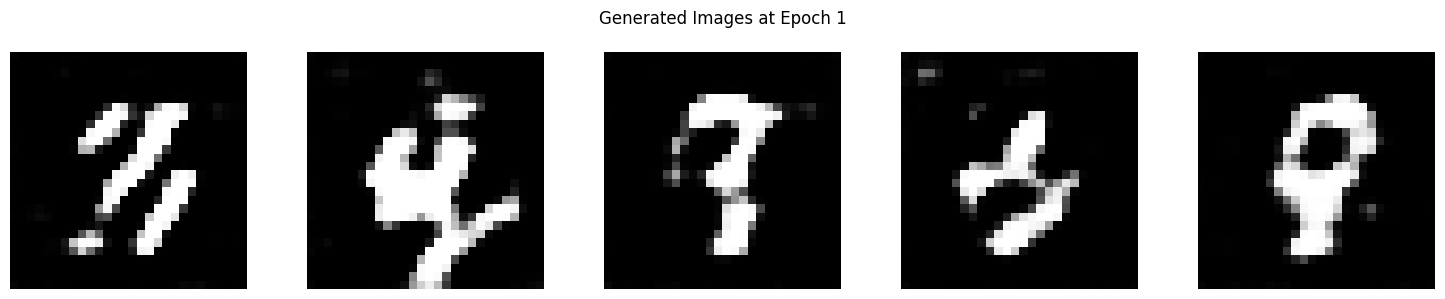

Epoch [2/50], Batch [0/469], D Loss: 1.0260, G Loss: 1.8810
Epoch [2/50], Batch [100/469], D Loss: 0.4371, G Loss: 4.1731
Epoch [2/50], Batch [200/469], D Loss: 0.7661, G Loss: 1.4520
Epoch [2/50], Batch [300/469], D Loss: 0.3980, G Loss: 3.9652
Epoch [2/50], Batch [400/469], D Loss: 0.3765, G Loss: 4.3912
Epoch [2/50] complete. Avg D Loss: 0.5537, Avg G Loss: 3.1650


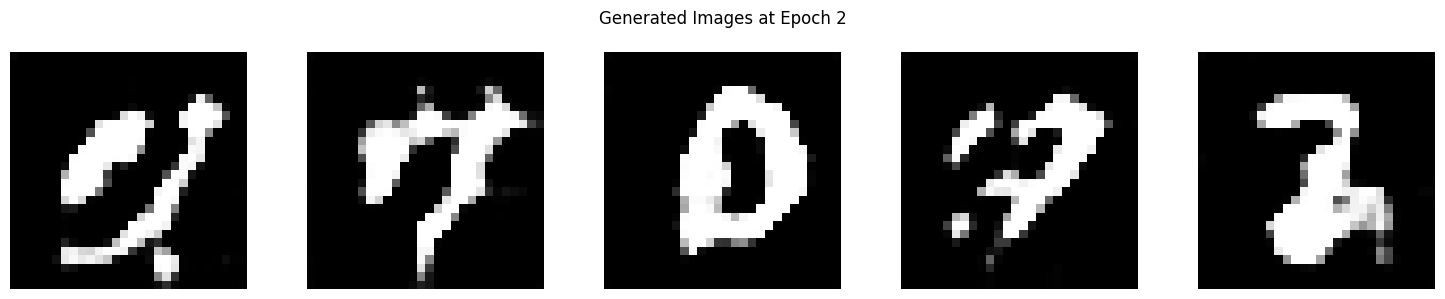

Epoch [3/50], Batch [0/469], D Loss: 0.4798, G Loss: 2.5344
Epoch [3/50], Batch [100/469], D Loss: 0.4902, G Loss: 3.2237
Epoch [3/50], Batch [200/469], D Loss: 0.4023, G Loss: 3.8137
Epoch [3/50], Batch [300/469], D Loss: 0.4912, G Loss: 3.5613
Epoch [3/50], Batch [400/469], D Loss: 0.4486, G Loss: 3.6414
Epoch [3/50] complete. Avg D Loss: 0.4562, Avg G Loss: 3.4023


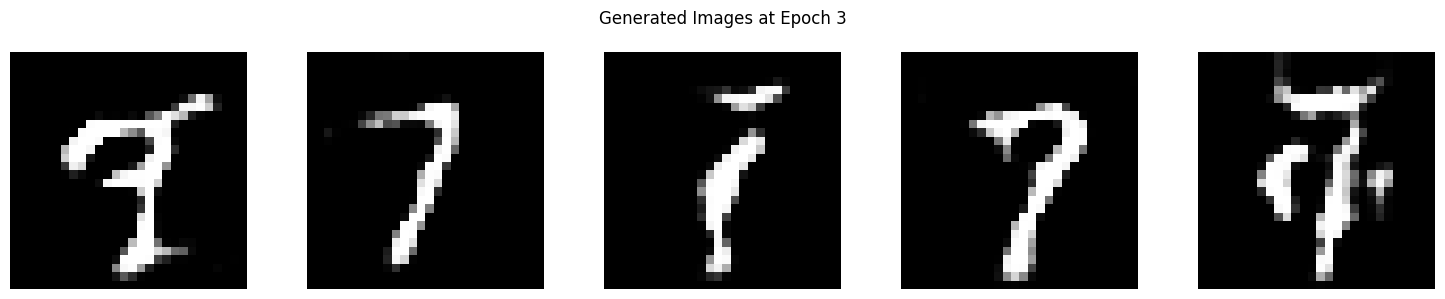

Epoch [4/50], Batch [0/469], D Loss: 0.4997, G Loss: 3.0641
Epoch [4/50], Batch [100/469], D Loss: 0.4190, G Loss: 3.5177
Epoch [4/50], Batch [200/469], D Loss: 0.4687, G Loss: 3.6131
Epoch [4/50], Batch [300/469], D Loss: 0.4360, G Loss: 2.4152
Epoch [4/50], Batch [400/469], D Loss: 0.5267, G Loss: 3.5903
Epoch [4/50] complete. Avg D Loss: 0.4990, Avg G Loss: 2.9940


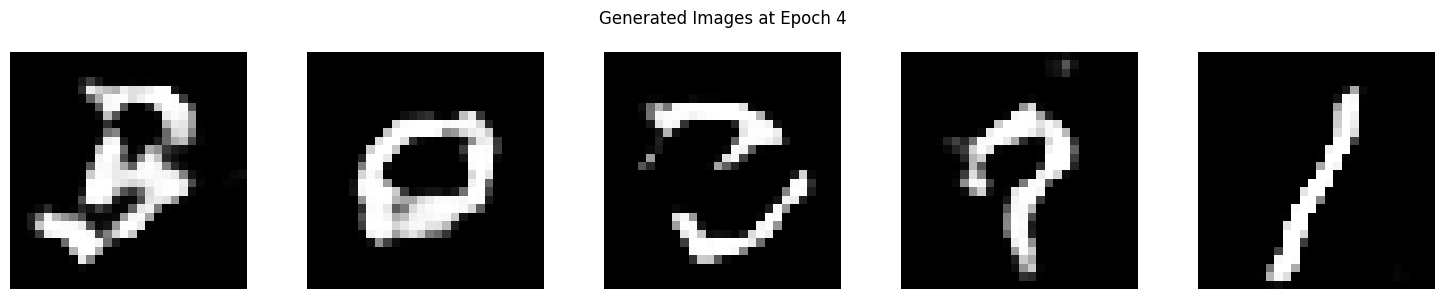

Epoch [5/50], Batch [0/469], D Loss: 0.4640, G Loss: 2.5613
Epoch [5/50], Batch [100/469], D Loss: 0.5015, G Loss: 2.7344
Epoch [5/50], Batch [200/469], D Loss: 0.7210, G Loss: 2.5996
Epoch [5/50], Batch [300/469], D Loss: 0.5009, G Loss: 2.4253
Epoch [5/50], Batch [400/469], D Loss: 0.9722, G Loss: 2.1161
Epoch [5/50] complete. Avg D Loss: 0.5708, Avg G Loss: 2.7708


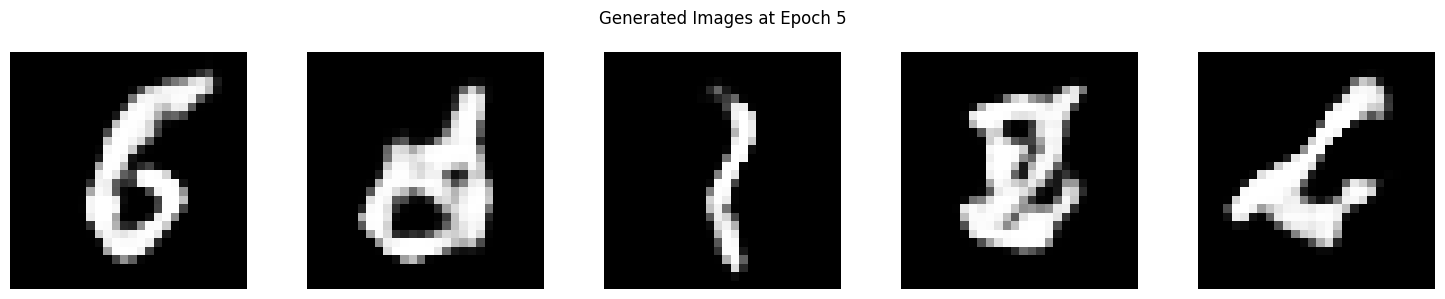

Epoch [6/50], Batch [0/469], D Loss: 0.6232, G Loss: 2.8136
Epoch [6/50], Batch [100/469], D Loss: 0.5280, G Loss: 2.2122
Epoch [6/50], Batch [200/469], D Loss: 0.5292, G Loss: 2.4372
Epoch [6/50], Batch [300/469], D Loss: 0.5295, G Loss: 2.5661
Epoch [6/50], Batch [400/469], D Loss: 0.5466, G Loss: 1.7229
Epoch [6/50] complete. Avg D Loss: 0.5411, Avg G Loss: 2.8181


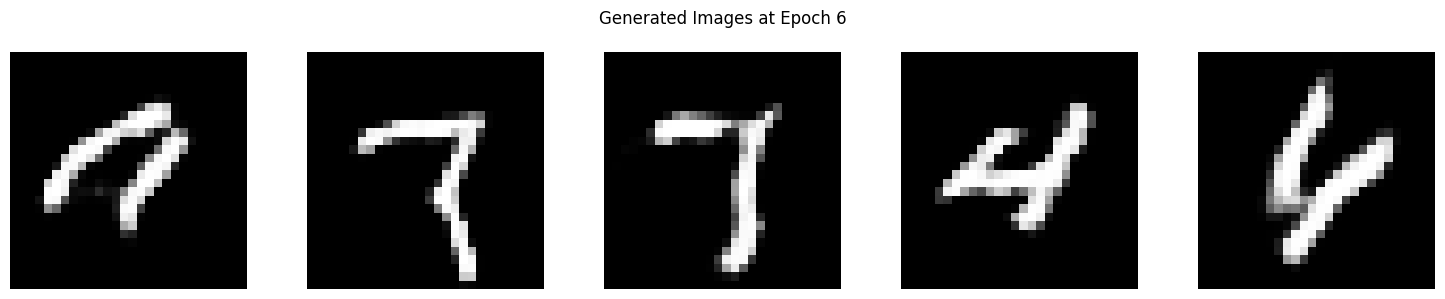

Epoch [7/50], Batch [0/469], D Loss: 0.7786, G Loss: 2.5068
Epoch [7/50], Batch [100/469], D Loss: 0.5491, G Loss: 3.4391
Epoch [7/50], Batch [200/469], D Loss: 0.4936, G Loss: 2.3790
Epoch [7/50], Batch [300/469], D Loss: 0.5775, G Loss: 3.0840
Epoch [7/50], Batch [400/469], D Loss: 0.5689, G Loss: 3.5297
Epoch [7/50] complete. Avg D Loss: 0.5707, Avg G Loss: 2.8582


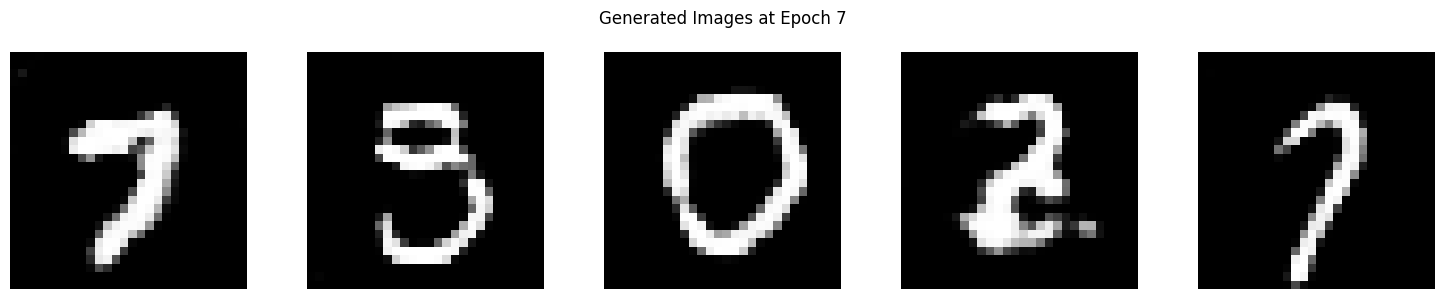

Epoch [8/50], Batch [0/469], D Loss: 1.3994, G Loss: 2.1913
Epoch [8/50], Batch [100/469], D Loss: 0.5839, G Loss: 2.5074
Epoch [8/50], Batch [200/469], D Loss: 0.6030, G Loss: 2.6638
Epoch [8/50], Batch [300/469], D Loss: 0.5279, G Loss: 2.9580
Epoch [8/50], Batch [400/469], D Loss: 0.5778, G Loss: 2.8014
Epoch [8/50] complete. Avg D Loss: 0.5968, Avg G Loss: 2.7243


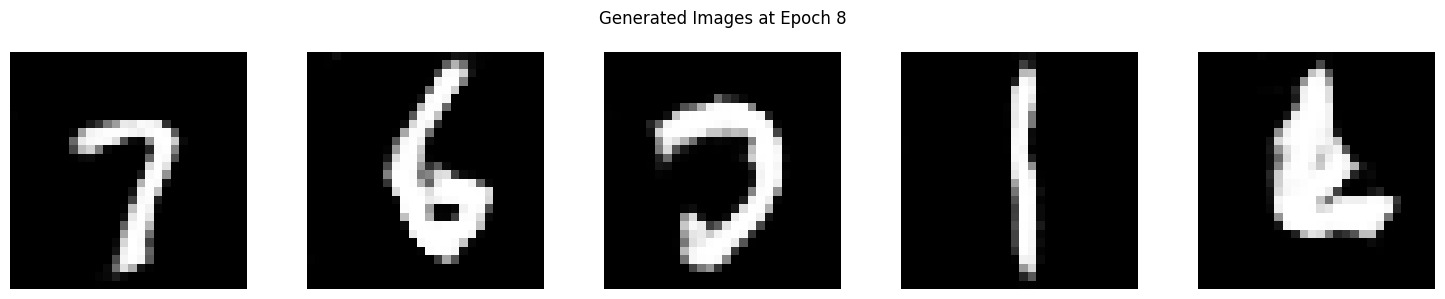

Epoch [9/50], Batch [0/469], D Loss: 0.4879, G Loss: 3.2314
Epoch [9/50], Batch [100/469], D Loss: 0.8542, G Loss: 1.7497
Epoch [9/50], Batch [200/469], D Loss: 0.6484, G Loss: 2.4015
Epoch [9/50], Batch [300/469], D Loss: 0.6969, G Loss: 3.1301
Epoch [9/50], Batch [400/469], D Loss: 0.6094, G Loss: 2.0907
Epoch [9/50] complete. Avg D Loss: 0.5761, Avg G Loss: 2.6964


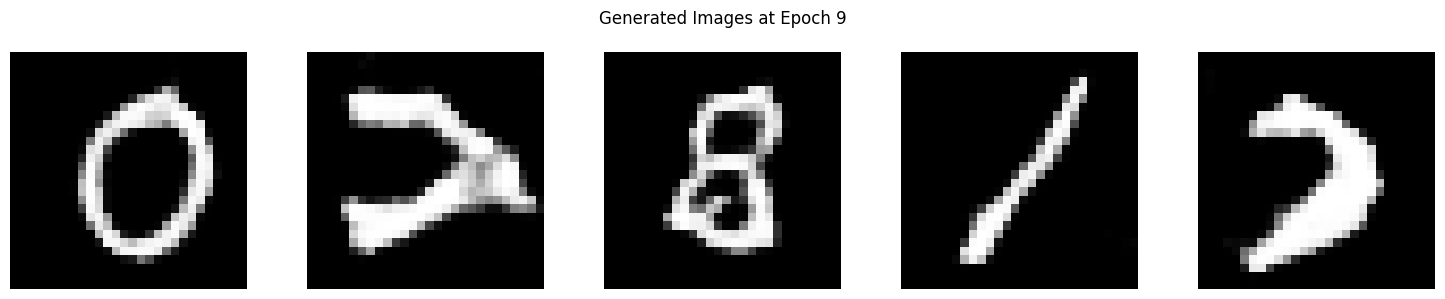

Epoch [10/50], Batch [0/469], D Loss: 0.5942, G Loss: 2.5523
Epoch [10/50], Batch [100/469], D Loss: 0.5654, G Loss: 1.8287
Epoch [10/50], Batch [200/469], D Loss: 0.7642, G Loss: 1.9470
Epoch [10/50], Batch [300/469], D Loss: 0.4375, G Loss: 3.6988
Epoch [10/50], Batch [400/469], D Loss: 0.7696, G Loss: 2.9229
Epoch [10/50] complete. Avg D Loss: 0.6145, Avg G Loss: 2.5867


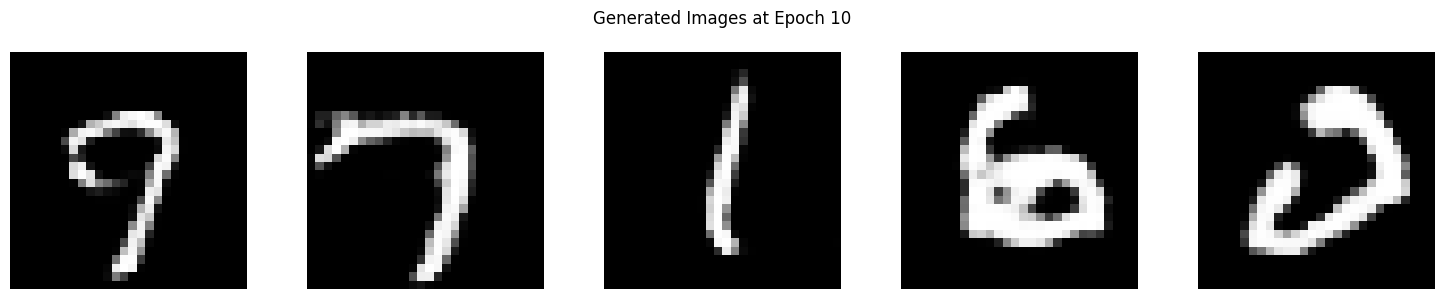

Epoch [11/50], Batch [0/469], D Loss: 0.5589, G Loss: 2.3491
Epoch [11/50], Batch [100/469], D Loss: 0.5340, G Loss: 2.1357
Epoch [11/50], Batch [200/469], D Loss: 0.5654, G Loss: 2.2200
Epoch [11/50], Batch [300/469], D Loss: 0.7317, G Loss: 1.6912
Epoch [11/50], Batch [400/469], D Loss: 0.5647, G Loss: 3.5411
Epoch [11/50] complete. Avg D Loss: 0.5885, Avg G Loss: 2.5868


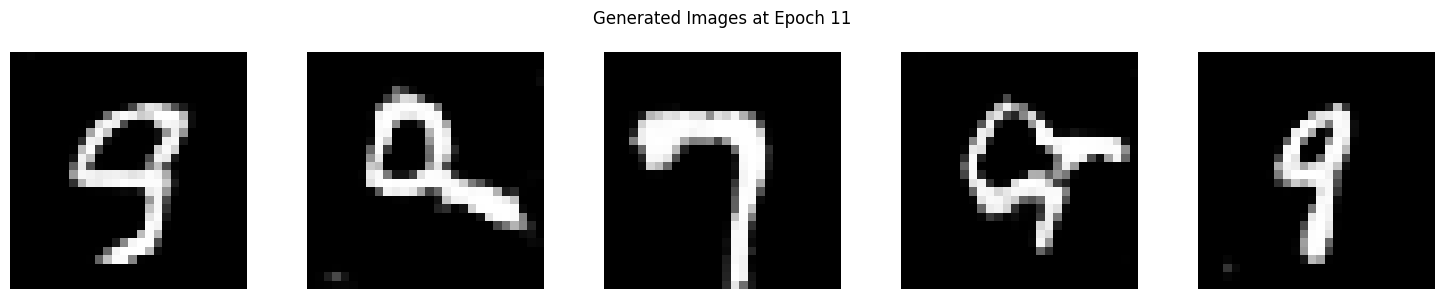

Epoch [12/50], Batch [0/469], D Loss: 0.6434, G Loss: 1.3679
Epoch [12/50], Batch [100/469], D Loss: 0.6995, G Loss: 3.2363
Epoch [12/50], Batch [200/469], D Loss: 0.6839, G Loss: 1.7611
Epoch [12/50], Batch [300/469], D Loss: 0.7560, G Loss: 4.4041
Epoch [12/50], Batch [400/469], D Loss: 0.5834, G Loss: 2.0541
Epoch [12/50] complete. Avg D Loss: 0.6246, Avg G Loss: 2.5353


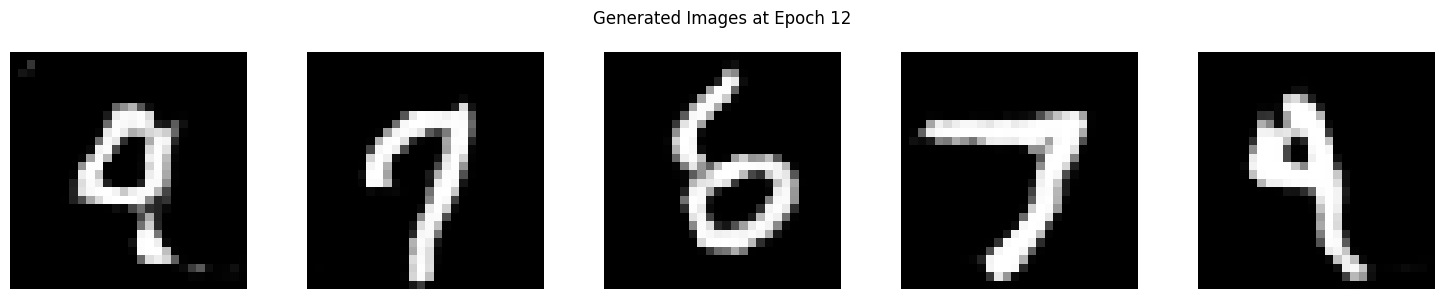

Epoch [13/50], Batch [0/469], D Loss: 0.6091, G Loss: 3.6646
Epoch [13/50], Batch [100/469], D Loss: 0.7388, G Loss: 3.4354
Epoch [13/50], Batch [200/469], D Loss: 0.8586, G Loss: 2.3275
Epoch [13/50], Batch [300/469], D Loss: 0.6734, G Loss: 2.5004
Epoch [13/50], Batch [400/469], D Loss: 0.4796, G Loss: 4.0367
Epoch [13/50] complete. Avg D Loss: 0.6129, Avg G Loss: 2.5226


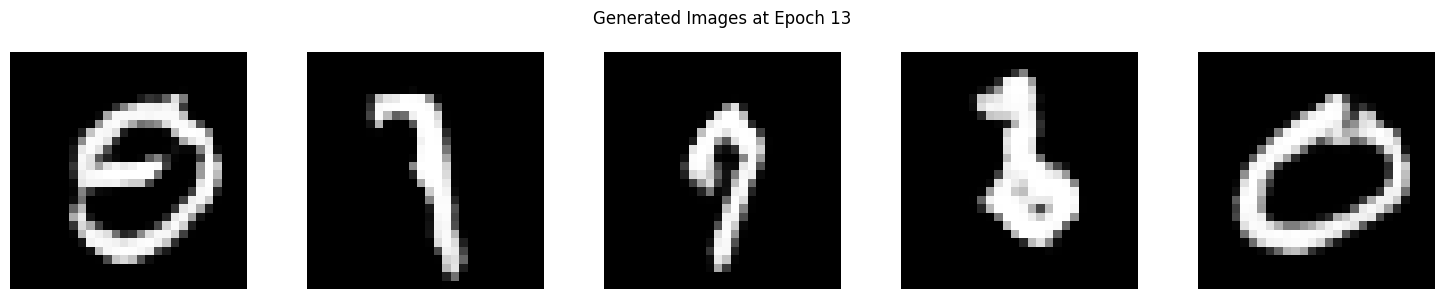

Epoch [14/50], Batch [0/469], D Loss: 0.6126, G Loss: 2.1088
Epoch [14/50], Batch [100/469], D Loss: 0.5067, G Loss: 2.7985
Epoch [14/50], Batch [200/469], D Loss: 0.6144, G Loss: 2.2274
Epoch [14/50], Batch [300/469], D Loss: 0.4256, G Loss: 3.3279
Epoch [14/50], Batch [400/469], D Loss: 0.6025, G Loss: 3.4822
Epoch [14/50] complete. Avg D Loss: 0.6310, Avg G Loss: 2.5228


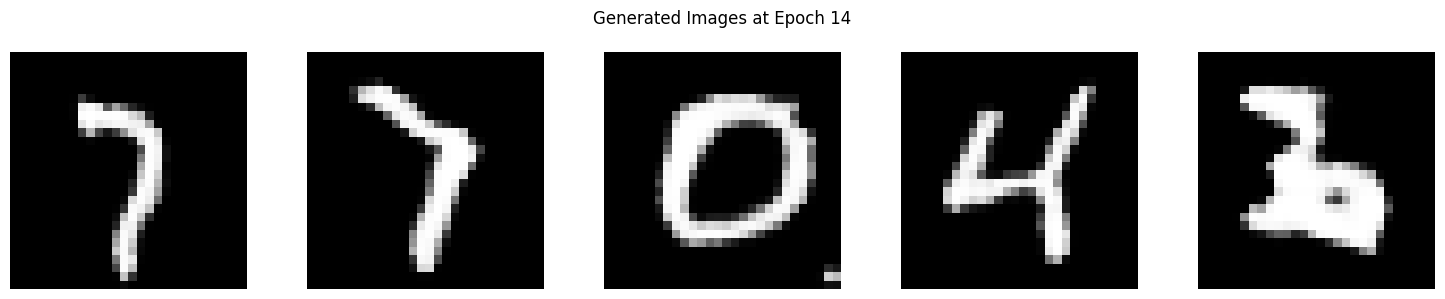

Epoch [15/50], Batch [0/469], D Loss: 0.9149, G Loss: 1.2227
Epoch [15/50], Batch [100/469], D Loss: 0.5168, G Loss: 2.8554
Epoch [15/50], Batch [200/469], D Loss: 0.6444, G Loss: 1.6987
Epoch [15/50], Batch [300/469], D Loss: 0.5981, G Loss: 3.5986
Epoch [15/50], Batch [400/469], D Loss: 0.6708, G Loss: 2.8275
Epoch [15/50] complete. Avg D Loss: 0.6355, Avg G Loss: 2.4072


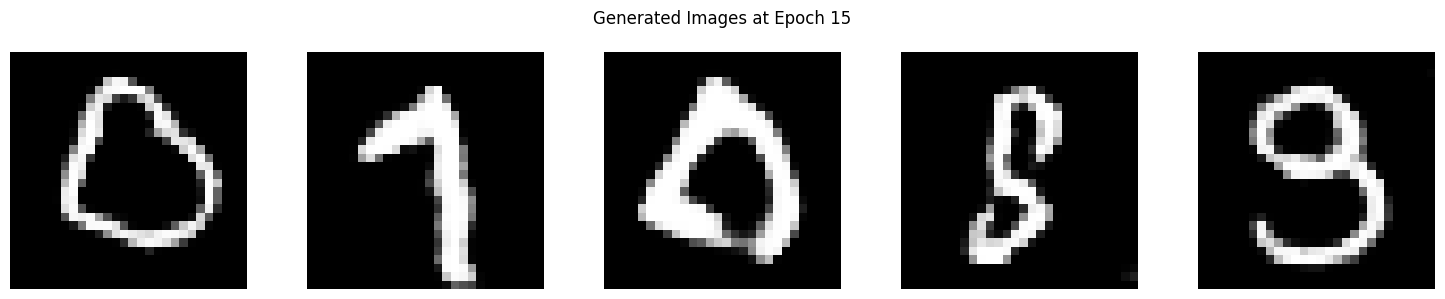

Epoch [16/50], Batch [0/469], D Loss: 0.5149, G Loss: 2.1268
Epoch [16/50], Batch [100/469], D Loss: 0.4849, G Loss: 3.1898
Epoch [16/50], Batch [200/469], D Loss: 0.7761, G Loss: 1.7240
Epoch [16/50], Batch [300/469], D Loss: 0.5336, G Loss: 3.4125
Epoch [16/50], Batch [400/469], D Loss: 0.7896, G Loss: 3.3062
Epoch [16/50] complete. Avg D Loss: 0.6521, Avg G Loss: 2.4263


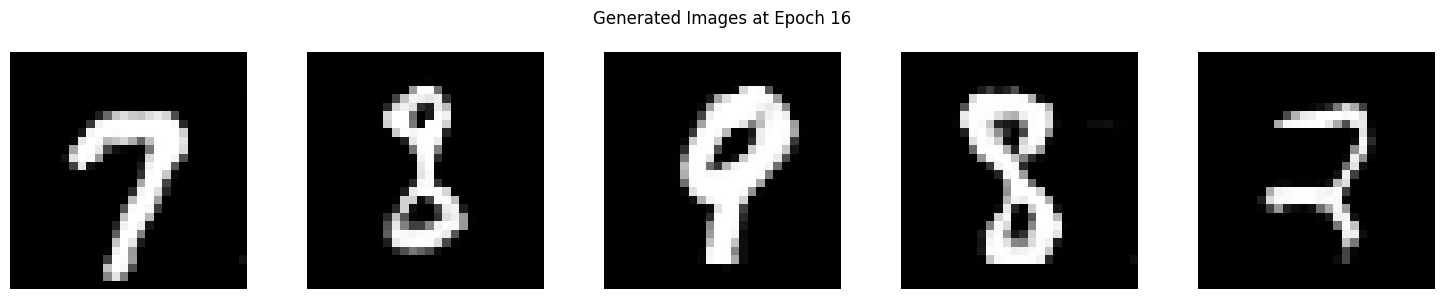

Epoch [17/50], Batch [0/469], D Loss: 0.5167, G Loss: 1.9837
Epoch [17/50], Batch [100/469], D Loss: 0.7415, G Loss: 2.3099
Epoch [17/50], Batch [200/469], D Loss: 0.4538, G Loss: 2.5347
Epoch [17/50], Batch [300/469], D Loss: 0.7045, G Loss: 2.1655
Epoch [17/50], Batch [400/469], D Loss: 0.6684, G Loss: 0.7778
Epoch [17/50] complete. Avg D Loss: 0.6559, Avg G Loss: 2.3697


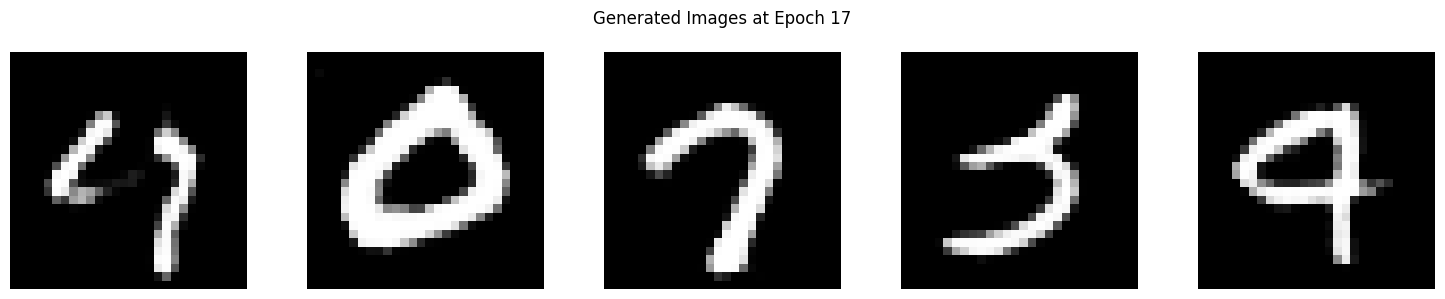

Epoch [18/50], Batch [0/469], D Loss: 0.6782, G Loss: 2.0027
Epoch [18/50], Batch [100/469], D Loss: 0.7058, G Loss: 1.9517
Epoch [18/50], Batch [200/469], D Loss: 0.6242, G Loss: 2.1316
Epoch [18/50], Batch [300/469], D Loss: 0.5679, G Loss: 2.6053
Epoch [18/50], Batch [400/469], D Loss: 0.6821, G Loss: 2.0503
Epoch [18/50] complete. Avg D Loss: 0.6589, Avg G Loss: 2.3789


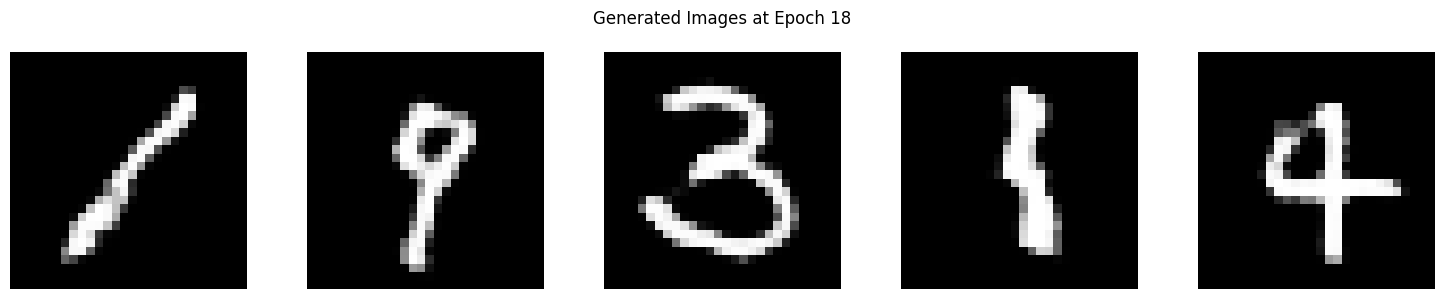

Epoch [19/50], Batch [0/469], D Loss: 0.5338, G Loss: 1.6139
Epoch [19/50], Batch [100/469], D Loss: 0.5455, G Loss: 1.8792
Epoch [19/50], Batch [200/469], D Loss: 0.8961, G Loss: 2.1302
Epoch [19/50], Batch [300/469], D Loss: 0.6123, G Loss: 1.7415
Epoch [19/50], Batch [400/469], D Loss: 0.8033, G Loss: 2.6230
Epoch [19/50] complete. Avg D Loss: 0.6661, Avg G Loss: 2.3197


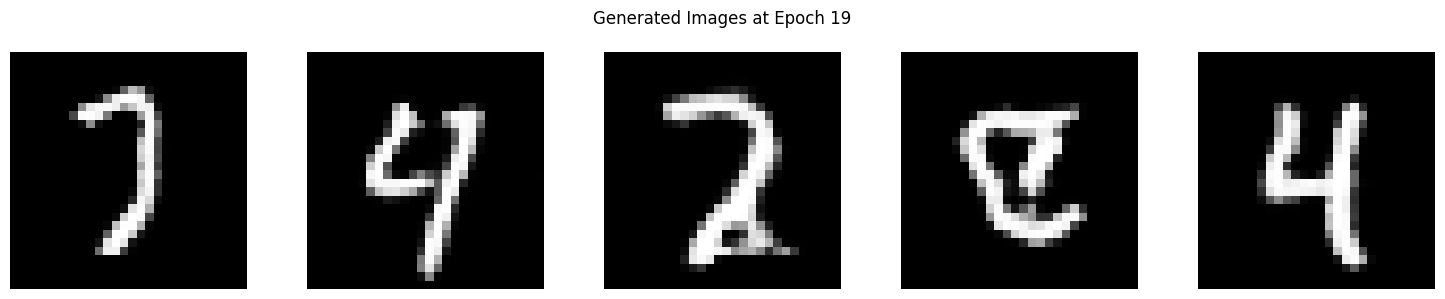

Epoch [20/50], Batch [0/469], D Loss: 0.6336, G Loss: 1.5551
Epoch [20/50], Batch [100/469], D Loss: 0.6613, G Loss: 2.6214
Epoch [20/50], Batch [200/469], D Loss: 0.6449, G Loss: 2.8530
Epoch [20/50], Batch [300/469], D Loss: 0.6460, G Loss: 2.3827
Epoch [20/50], Batch [400/469], D Loss: 0.6012, G Loss: 2.5684
Epoch [20/50] complete. Avg D Loss: 0.6616, Avg G Loss: 2.3531


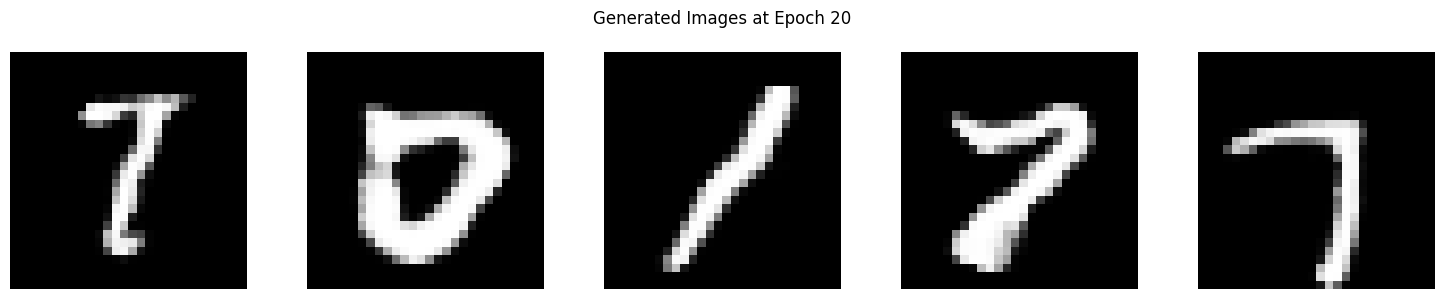

Epoch [21/50], Batch [0/469], D Loss: 0.7082, G Loss: 2.4982
Epoch [21/50], Batch [100/469], D Loss: 0.5495, G Loss: 2.5124
Epoch [21/50], Batch [200/469], D Loss: 0.6614, G Loss: 2.5273
Epoch [21/50], Batch [300/469], D Loss: 0.7118, G Loss: 2.3137
Epoch [21/50], Batch [400/469], D Loss: 0.7270, G Loss: 2.0783
Epoch [21/50] complete. Avg D Loss: 0.6612, Avg G Loss: 2.3450


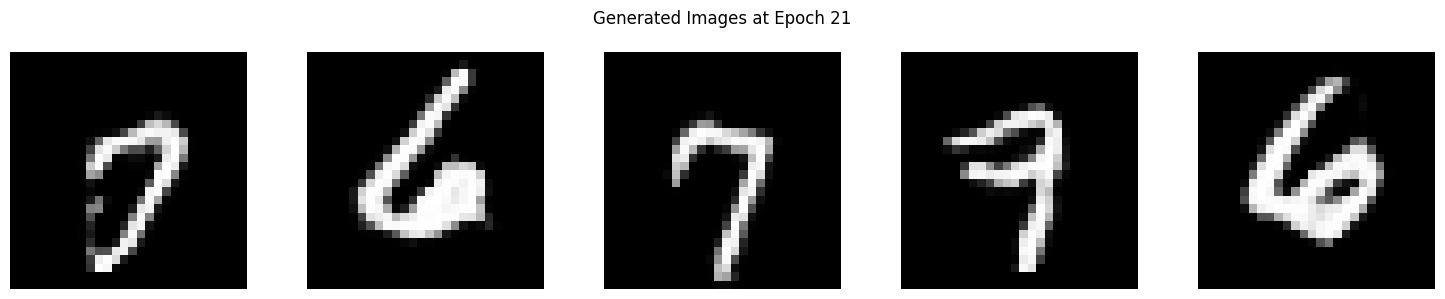

Epoch [22/50], Batch [0/469], D Loss: 0.6658, G Loss: 1.1514
Epoch [22/50], Batch [100/469], D Loss: 0.7407, G Loss: 1.5019
Epoch [22/50], Batch [200/469], D Loss: 0.5436, G Loss: 2.4346
Epoch [22/50], Batch [300/469], D Loss: 0.6389, G Loss: 2.7382
Epoch [22/50], Batch [400/469], D Loss: 0.6001, G Loss: 1.8278
Epoch [22/50] complete. Avg D Loss: 0.6800, Avg G Loss: 2.3373


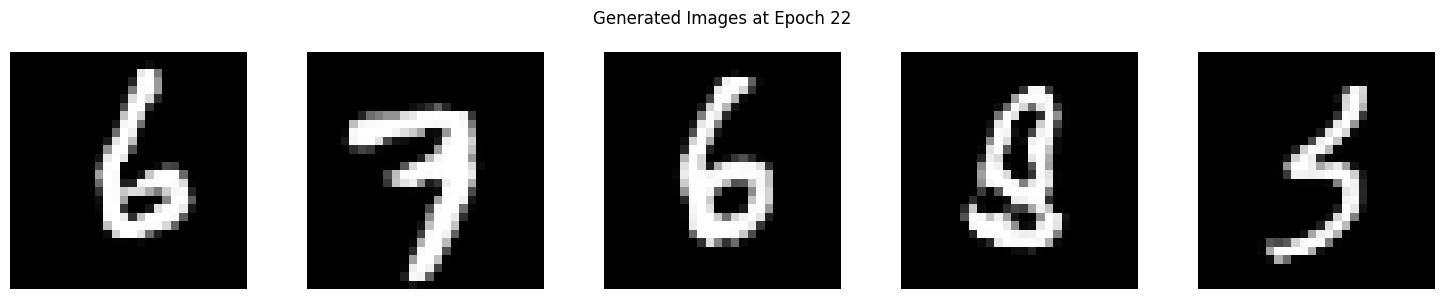

Epoch [23/50], Batch [0/469], D Loss: 0.4743, G Loss: 2.1549
Epoch [23/50], Batch [100/469], D Loss: 1.2319, G Loss: 3.1585
Epoch [23/50], Batch [200/469], D Loss: 0.6167, G Loss: 1.8889
Epoch [23/50], Batch [300/469], D Loss: 0.6102, G Loss: 1.8470
Epoch [23/50], Batch [400/469], D Loss: 0.9617, G Loss: 1.5487
Epoch [23/50] complete. Avg D Loss: 0.6714, Avg G Loss: 2.3058


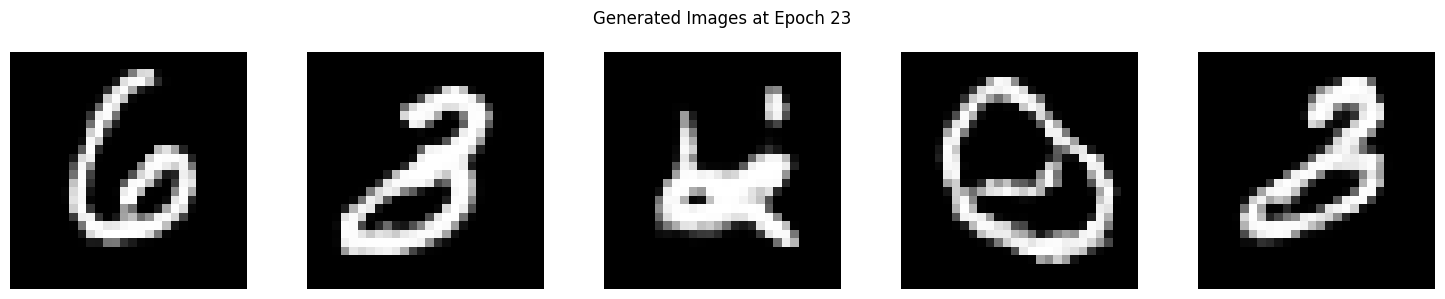

Epoch [24/50], Batch [0/469], D Loss: 0.5810, G Loss: 2.5023
Epoch [24/50], Batch [100/469], D Loss: 0.7789, G Loss: 2.0945
Epoch [24/50], Batch [200/469], D Loss: 0.5651, G Loss: 3.1199
Epoch [24/50], Batch [300/469], D Loss: 0.4964, G Loss: 3.3052
Epoch [24/50], Batch [400/469], D Loss: 0.9144, G Loss: 2.4346
Epoch [24/50] complete. Avg D Loss: 0.6600, Avg G Loss: 2.3281


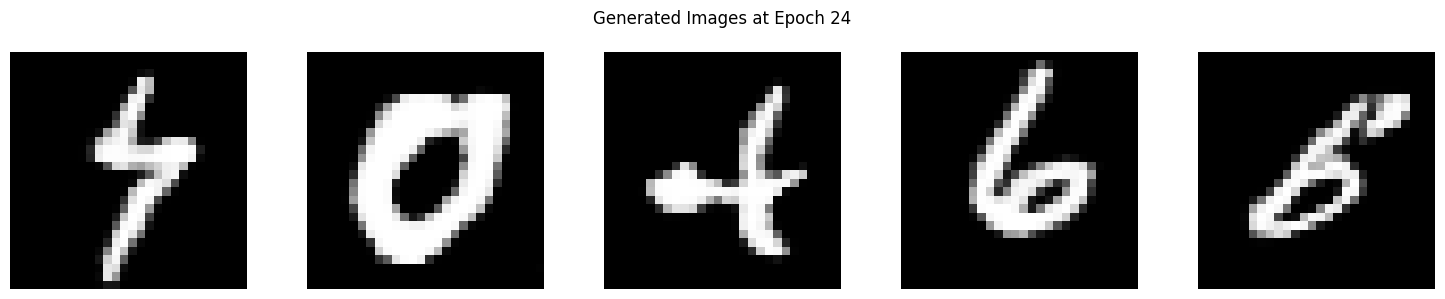

Epoch [25/50], Batch [0/469], D Loss: 0.6741, G Loss: 2.0817
Epoch [25/50], Batch [100/469], D Loss: 0.6902, G Loss: 1.7934
Epoch [25/50], Batch [200/469], D Loss: 0.7595, G Loss: 2.0052
Epoch [25/50], Batch [300/469], D Loss: 0.6101, G Loss: 2.1093
Epoch [25/50], Batch [400/469], D Loss: 0.9702, G Loss: 1.1173
Epoch [25/50] complete. Avg D Loss: 0.6990, Avg G Loss: 2.3146


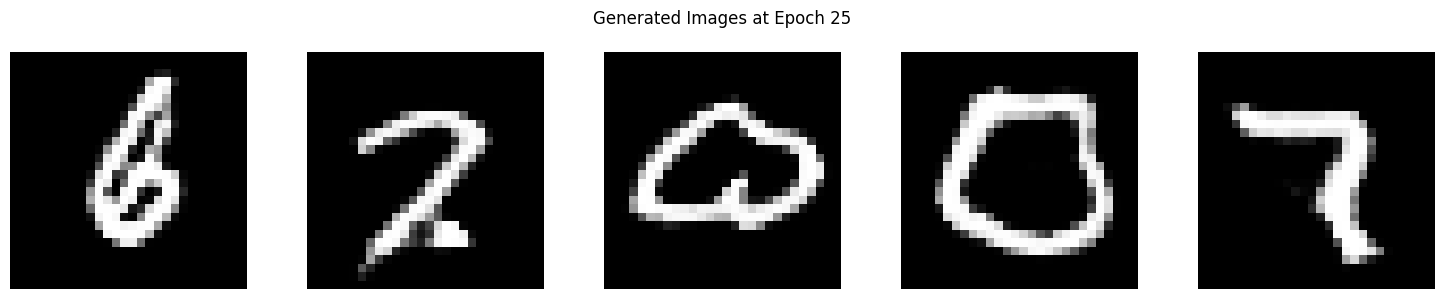

Epoch [26/50], Batch [0/469], D Loss: 0.5615, G Loss: 1.8430
Epoch [26/50], Batch [100/469], D Loss: 0.7393, G Loss: 1.9053
Epoch [26/50], Batch [200/469], D Loss: 0.9407, G Loss: 1.9370
Epoch [26/50], Batch [300/469], D Loss: 1.1439, G Loss: 1.5637
Epoch [26/50], Batch [400/469], D Loss: 0.8921, G Loss: 1.6422
Epoch [26/50] complete. Avg D Loss: 0.6722, Avg G Loss: 2.2669


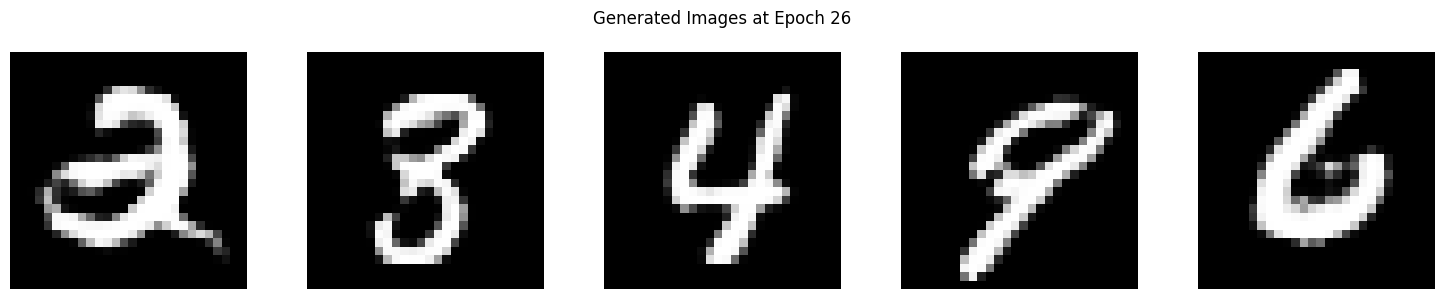

Epoch [27/50], Batch [0/469], D Loss: 0.5496, G Loss: 3.5235
Epoch [27/50], Batch [100/469], D Loss: 0.7968, G Loss: 1.9606
Epoch [27/50], Batch [200/469], D Loss: 0.8174, G Loss: 2.6727
Epoch [27/50], Batch [300/469], D Loss: 0.5197, G Loss: 2.6694
Epoch [27/50], Batch [400/469], D Loss: 0.6280, G Loss: 2.8560
Epoch [27/50] complete. Avg D Loss: 0.6903, Avg G Loss: 2.3621


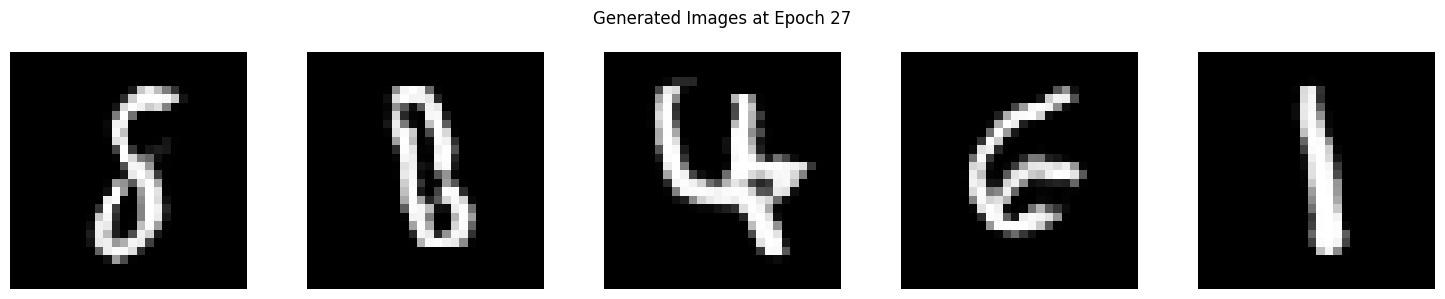

Epoch [28/50], Batch [0/469], D Loss: 0.6045, G Loss: 1.4124
Epoch [28/50], Batch [100/469], D Loss: 0.5450, G Loss: 2.7671
Epoch [28/50], Batch [200/469], D Loss: 0.8327, G Loss: 1.2541
Epoch [28/50], Batch [300/469], D Loss: 0.6834, G Loss: 1.6456
Epoch [28/50], Batch [400/469], D Loss: 0.7887, G Loss: 2.2402
Epoch [28/50] complete. Avg D Loss: 0.6876, Avg G Loss: 2.2192


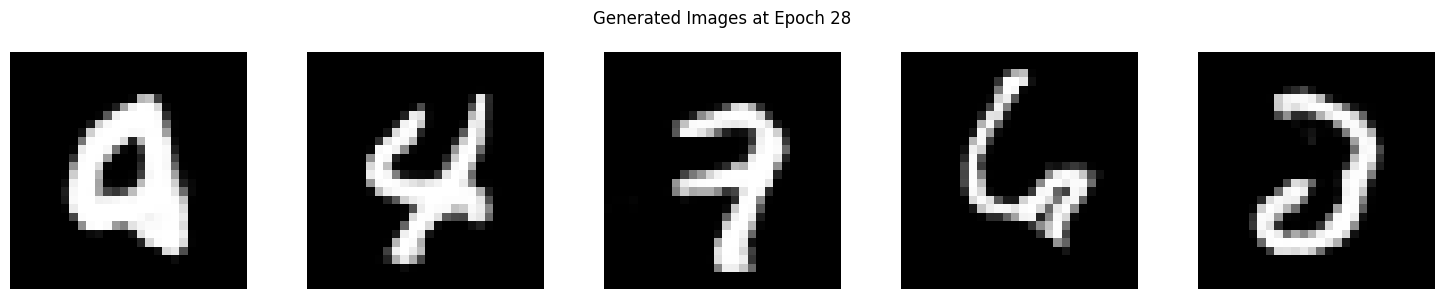

Epoch [29/50], Batch [0/469], D Loss: 0.8023, G Loss: 2.9227
Epoch [29/50], Batch [100/469], D Loss: 0.5663, G Loss: 2.7211
Epoch [29/50], Batch [200/469], D Loss: 0.5035, G Loss: 2.4325
Epoch [29/50], Batch [300/469], D Loss: 0.6502, G Loss: 2.7563
Epoch [29/50], Batch [400/469], D Loss: 0.7526, G Loss: 2.0956
Epoch [29/50] complete. Avg D Loss: 0.6803, Avg G Loss: 2.3412


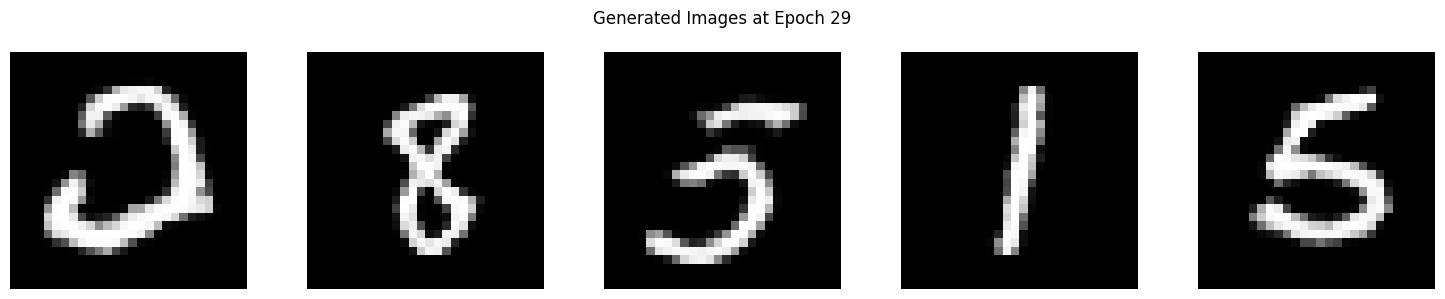

Epoch [30/50], Batch [0/469], D Loss: 0.4935, G Loss: 2.0197
Epoch [30/50], Batch [100/469], D Loss: 0.6381, G Loss: 1.9856
Epoch [30/50], Batch [200/469], D Loss: 0.5025, G Loss: 2.0074
Epoch [30/50], Batch [300/469], D Loss: 0.4930, G Loss: 2.3679
Epoch [30/50], Batch [400/469], D Loss: 0.6403, G Loss: 2.2028
Epoch [30/50] complete. Avg D Loss: 0.6941, Avg G Loss: 2.2539


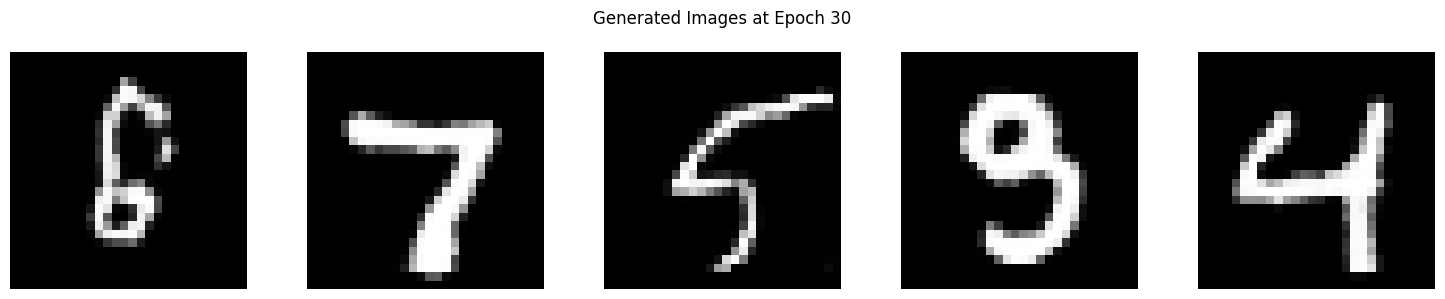

Epoch [31/50], Batch [0/469], D Loss: 0.8201, G Loss: 1.3217
Epoch [31/50], Batch [100/469], D Loss: 0.5392, G Loss: 3.2327
Epoch [31/50], Batch [200/469], D Loss: 0.6944, G Loss: 1.1804
Epoch [31/50], Batch [300/469], D Loss: 0.5312, G Loss: 1.9510
Epoch [31/50], Batch [400/469], D Loss: 0.6453, G Loss: 2.2334
Epoch [31/50] complete. Avg D Loss: 0.6803, Avg G Loss: 2.2308


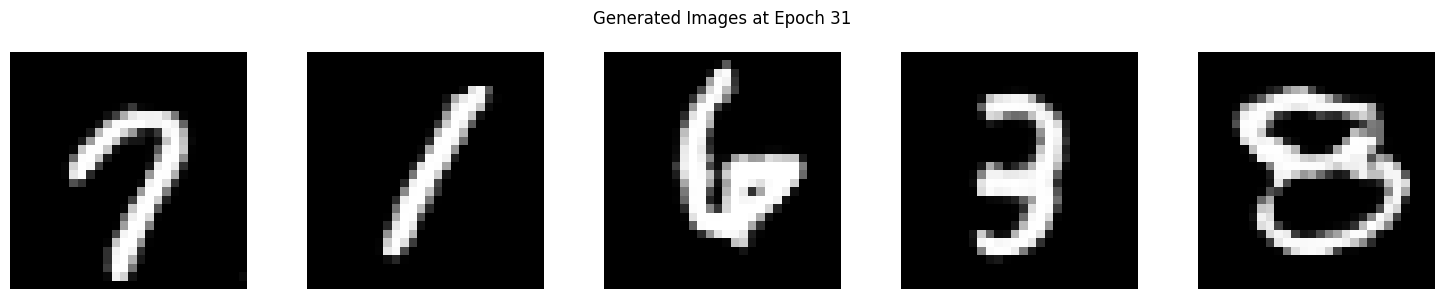

Epoch [32/50], Batch [0/469], D Loss: 0.7853, G Loss: 2.2434
Epoch [32/50], Batch [100/469], D Loss: 0.8542, G Loss: 1.7878
Epoch [32/50], Batch [200/469], D Loss: 0.6417, G Loss: 3.2075
Epoch [32/50], Batch [300/469], D Loss: 0.6308, G Loss: 1.8667
Epoch [32/50], Batch [400/469], D Loss: 0.6452, G Loss: 2.0445
Epoch [32/50] complete. Avg D Loss: 0.6927, Avg G Loss: 2.3035


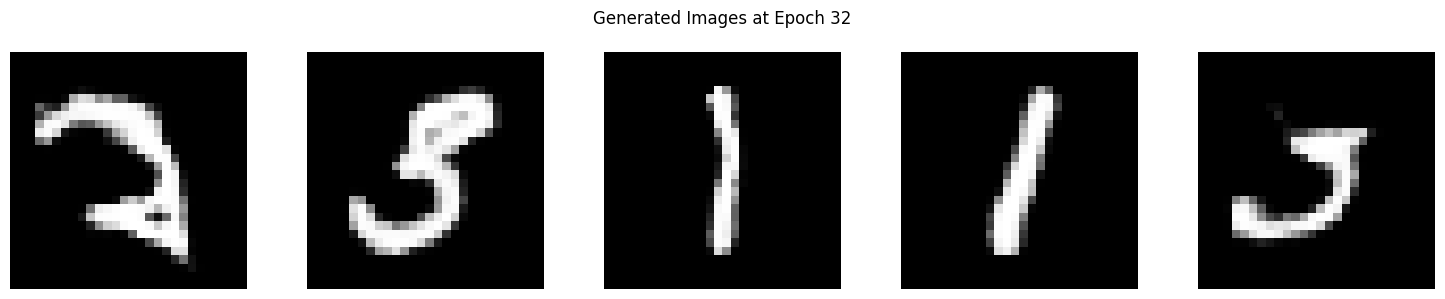

Epoch [33/50], Batch [0/469], D Loss: 0.7136, G Loss: 2.9716
Epoch [33/50], Batch [100/469], D Loss: 0.6647, G Loss: 1.5006
Epoch [33/50], Batch [200/469], D Loss: 0.4728, G Loss: 3.2278
Epoch [33/50], Batch [300/469], D Loss: 0.5748, G Loss: 4.3309
Epoch [33/50], Batch [400/469], D Loss: 1.0117, G Loss: 1.8330
Epoch [33/50] complete. Avg D Loss: 0.7034, Avg G Loss: 2.3655


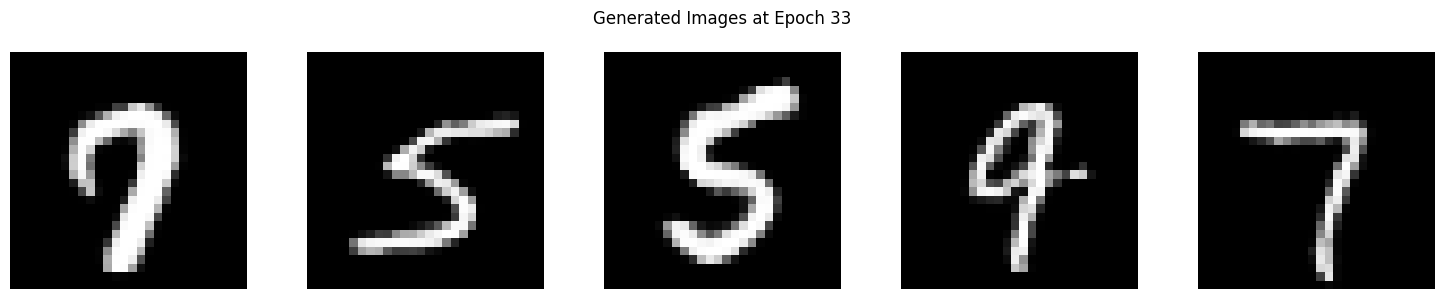

Epoch [34/50], Batch [0/469], D Loss: 0.8873, G Loss: 2.7681
Epoch [34/50], Batch [100/469], D Loss: 0.6577, G Loss: 2.4127
Epoch [34/50], Batch [200/469], D Loss: 0.7934, G Loss: 2.3207
Epoch [34/50], Batch [300/469], D Loss: 0.7151, G Loss: 2.3306
Epoch [34/50], Batch [400/469], D Loss: 0.6418, G Loss: 2.7282
Epoch [34/50] complete. Avg D Loss: 0.6778, Avg G Loss: 2.3203


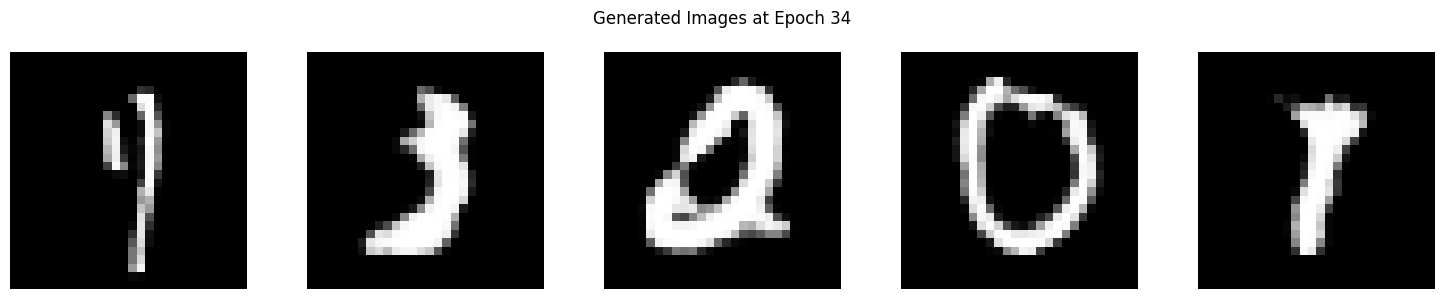

Epoch [35/50], Batch [0/469], D Loss: 0.5429, G Loss: 1.3571
Epoch [35/50], Batch [100/469], D Loss: 0.8349, G Loss: 1.4566
Epoch [35/50], Batch [200/469], D Loss: 0.4987, G Loss: 1.5874
Epoch [35/50], Batch [300/469], D Loss: 0.7953, G Loss: 2.3707
Epoch [35/50], Batch [400/469], D Loss: 0.9010, G Loss: 2.9811
Epoch [35/50] complete. Avg D Loss: 0.6917, Avg G Loss: 2.2783


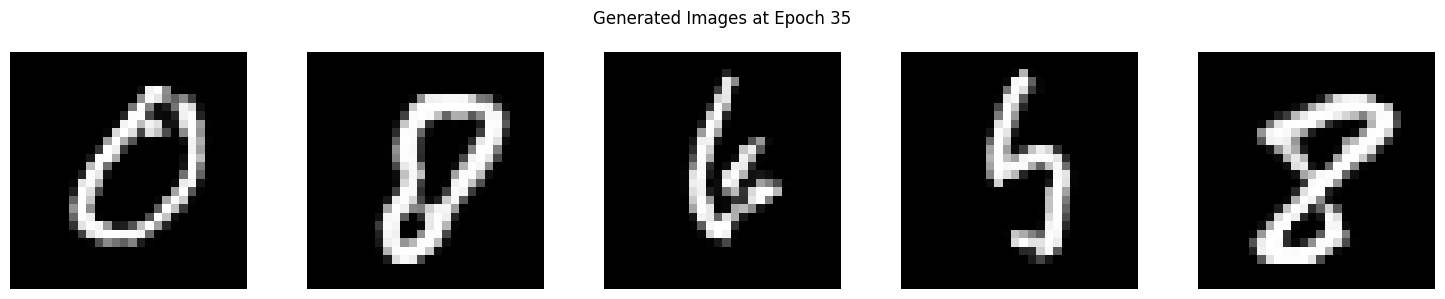

Epoch [36/50], Batch [0/469], D Loss: 0.6611, G Loss: 1.1307
Epoch [36/50], Batch [100/469], D Loss: 0.9662, G Loss: 2.4986
Epoch [36/50], Batch [200/469], D Loss: 0.6055, G Loss: 3.0274
Epoch [36/50], Batch [300/469], D Loss: 1.1356, G Loss: 3.8443
Epoch [36/50], Batch [400/469], D Loss: 0.4872, G Loss: 1.9667
Epoch [36/50] complete. Avg D Loss: 0.6881, Avg G Loss: 2.3488


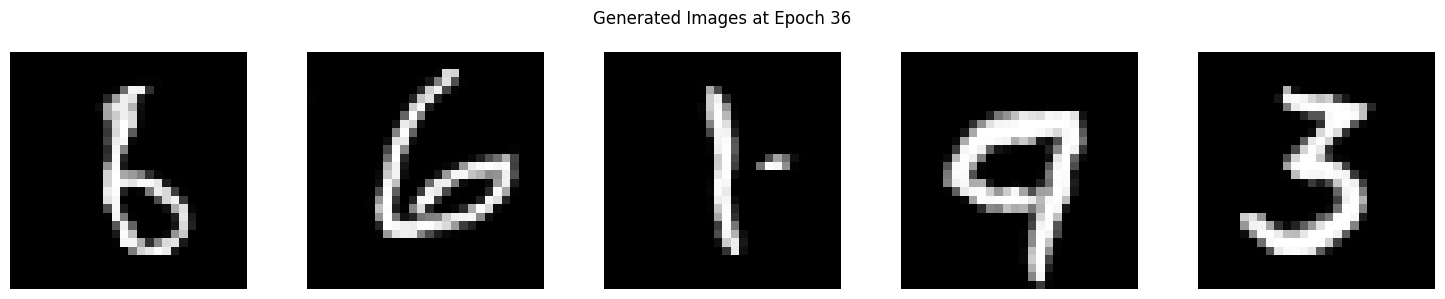

Epoch [37/50], Batch [0/469], D Loss: 0.5780, G Loss: 2.4488
Epoch [37/50], Batch [100/469], D Loss: 0.6091, G Loss: 2.2978
Epoch [37/50], Batch [200/469], D Loss: 0.5903, G Loss: 2.1702
Epoch [37/50], Batch [300/469], D Loss: 0.6049, G Loss: 2.4276
Epoch [37/50], Batch [400/469], D Loss: 0.8097, G Loss: 1.7283
Epoch [37/50] complete. Avg D Loss: 0.6697, Avg G Loss: 2.3219


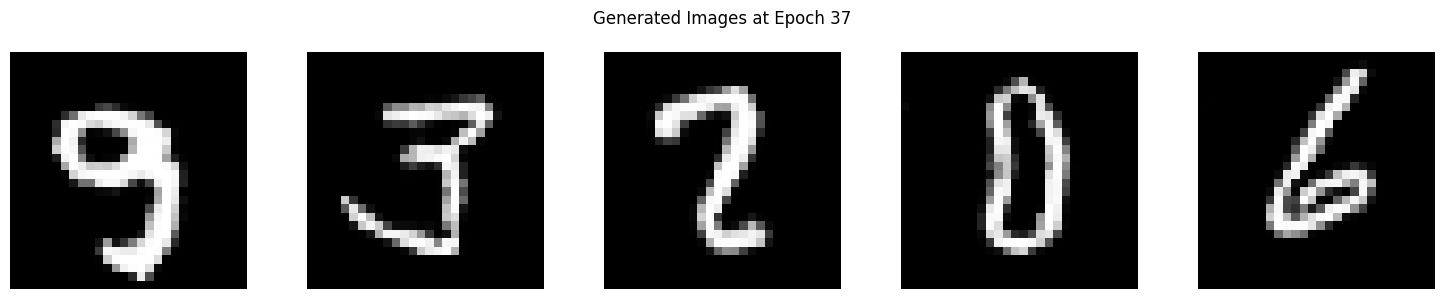

Epoch [38/50], Batch [0/469], D Loss: 1.0875, G Loss: 1.4451
Epoch [38/50], Batch [100/469], D Loss: 0.6529, G Loss: 2.9689
Epoch [38/50], Batch [200/469], D Loss: 0.6847, G Loss: 1.5649
Epoch [38/50], Batch [300/469], D Loss: 0.7794, G Loss: 1.7247
Epoch [38/50], Batch [400/469], D Loss: 0.9043, G Loss: 2.3940
Epoch [38/50] complete. Avg D Loss: 0.6874, Avg G Loss: 2.3447


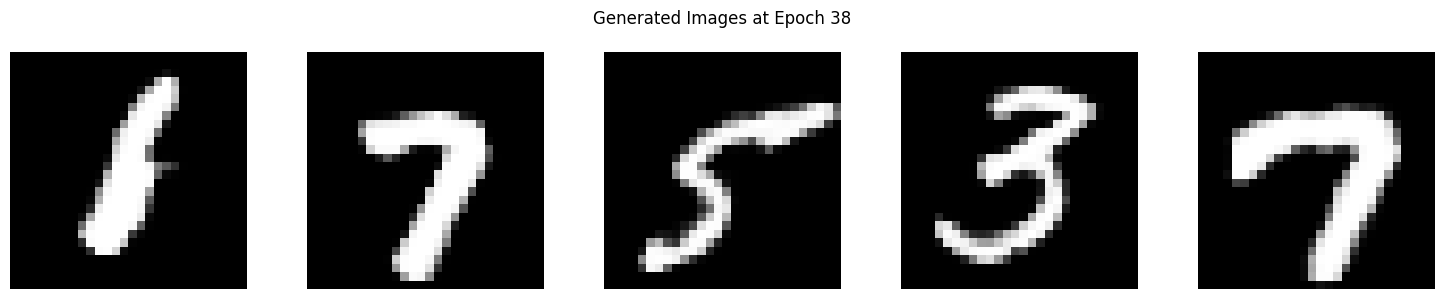

Epoch [39/50], Batch [0/469], D Loss: 0.5892, G Loss: 2.6300
Epoch [39/50], Batch [100/469], D Loss: 0.5183, G Loss: 2.3429
Epoch [39/50], Batch [200/469], D Loss: 0.6791, G Loss: 3.7213
Epoch [39/50], Batch [300/469], D Loss: 0.6893, G Loss: 1.5555
Epoch [39/50], Batch [400/469], D Loss: 0.5450, G Loss: 1.9779
Epoch [39/50] complete. Avg D Loss: 0.6681, Avg G Loss: 2.3159


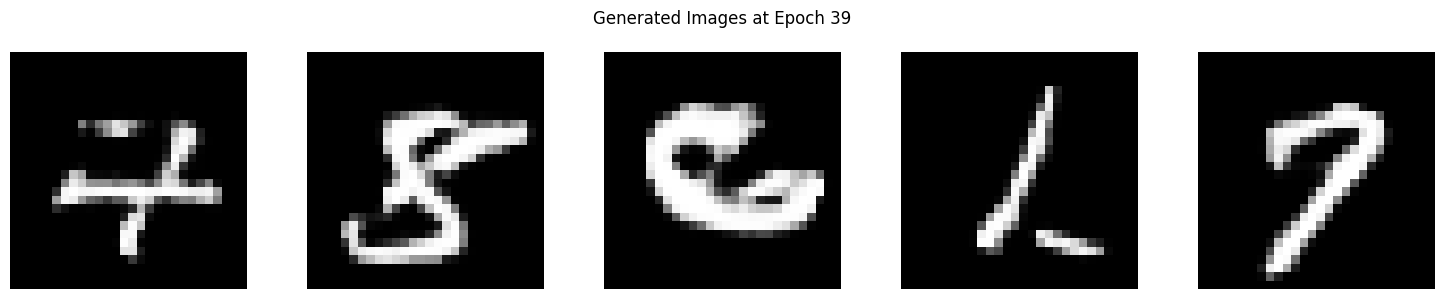

Epoch [40/50], Batch [0/469], D Loss: 0.8191, G Loss: 3.2934
Epoch [40/50], Batch [100/469], D Loss: 0.6905, G Loss: 1.3948
Epoch [40/50], Batch [200/469], D Loss: 0.5710, G Loss: 2.1675
Epoch [40/50], Batch [300/469], D Loss: 0.8043, G Loss: 3.0901
Epoch [40/50], Batch [400/469], D Loss: 0.7712, G Loss: 1.9157
Epoch [40/50] complete. Avg D Loss: 0.6838, Avg G Loss: 2.3401


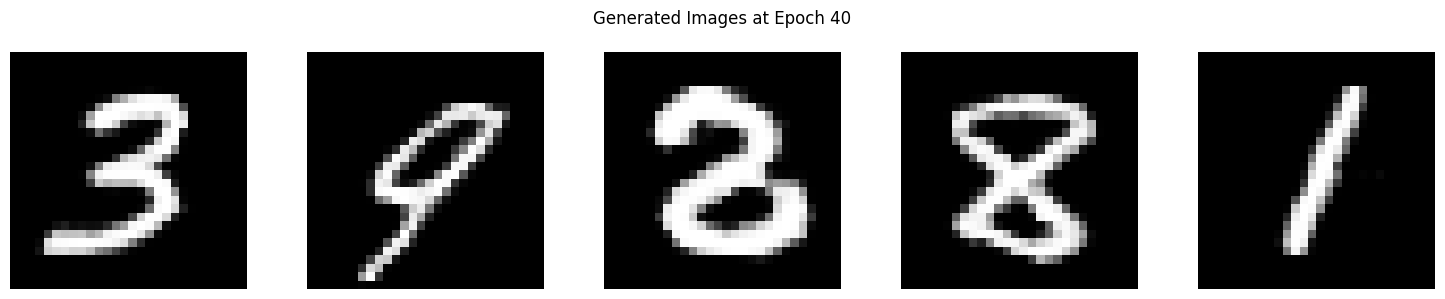

Epoch [41/50], Batch [0/469], D Loss: 0.5378, G Loss: 2.3304
Epoch [41/50], Batch [100/469], D Loss: 0.6478, G Loss: 2.8644
Epoch [41/50], Batch [200/469], D Loss: 0.7198, G Loss: 1.8994
Epoch [41/50], Batch [300/469], D Loss: 0.5137, G Loss: 2.9682
Epoch [41/50], Batch [400/469], D Loss: 0.6897, G Loss: 0.9876
Epoch [41/50] complete. Avg D Loss: 0.6742, Avg G Loss: 2.3852


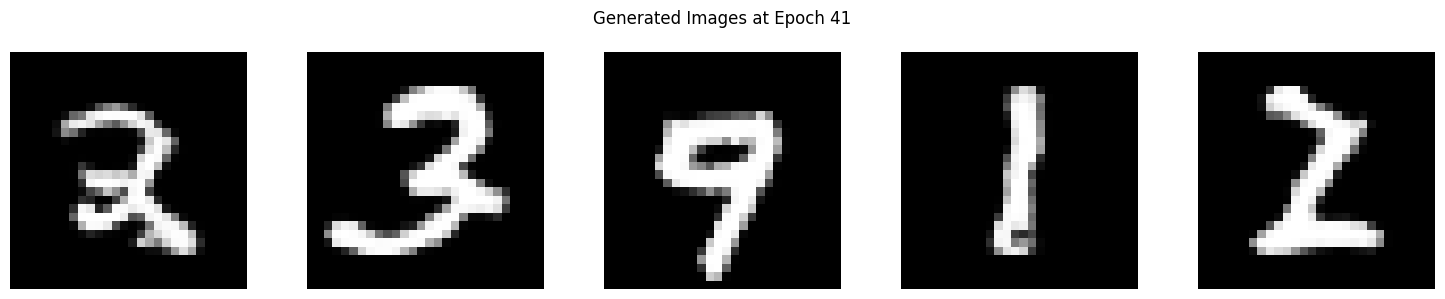

Epoch [42/50], Batch [0/469], D Loss: 0.6227, G Loss: 2.5156
Epoch [42/50], Batch [100/469], D Loss: 0.5125, G Loss: 1.4052
Epoch [42/50], Batch [200/469], D Loss: 0.7082, G Loss: 1.5671
Epoch [42/50], Batch [300/469], D Loss: 0.5887, G Loss: 1.4444
Epoch [42/50], Batch [400/469], D Loss: 0.8784, G Loss: 2.0249
Epoch [42/50] complete. Avg D Loss: 0.6618, Avg G Loss: 2.4401


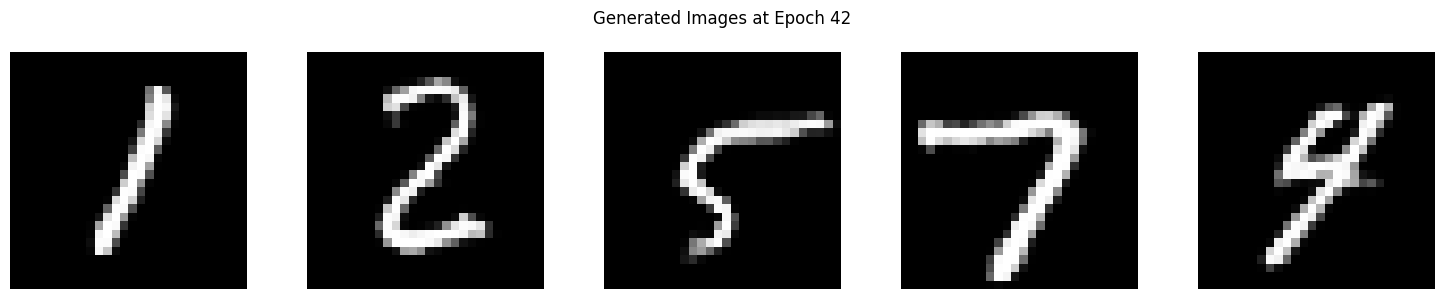

Epoch [43/50], Batch [0/469], D Loss: 0.6782, G Loss: 2.9413
Epoch [43/50], Batch [100/469], D Loss: 0.5278, G Loss: 2.9183
Epoch [43/50], Batch [200/469], D Loss: 1.1894, G Loss: 0.7726
Epoch [43/50], Batch [300/469], D Loss: 0.7195, G Loss: 2.0731
Epoch [43/50], Batch [400/469], D Loss: 0.6409, G Loss: 2.0777
Epoch [43/50] complete. Avg D Loss: 0.6801, Avg G Loss: 2.3624


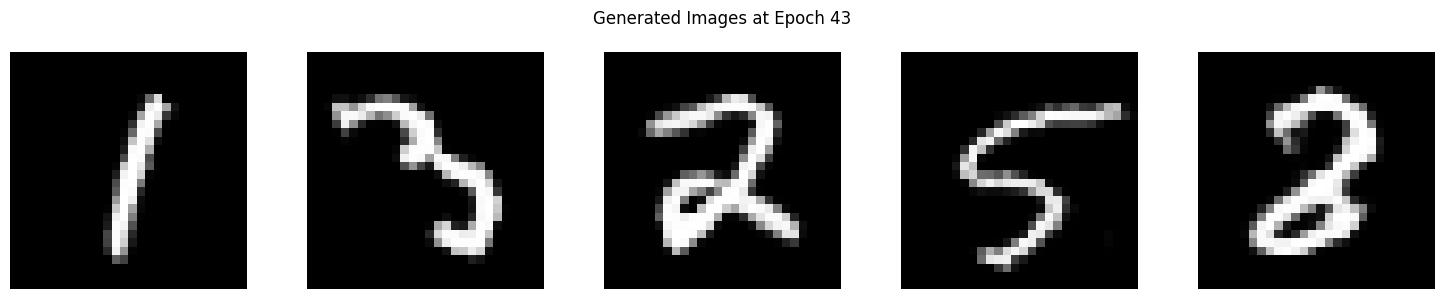

Epoch [44/50], Batch [0/469], D Loss: 0.7909, G Loss: 3.1416
Epoch [44/50], Batch [100/469], D Loss: 0.5335, G Loss: 3.1637
Epoch [44/50], Batch [200/469], D Loss: 0.5573, G Loss: 2.5567
Epoch [44/50], Batch [300/469], D Loss: 0.5505, G Loss: 2.4311
Epoch [44/50], Batch [400/469], D Loss: 0.6348, G Loss: 1.5747
Epoch [44/50] complete. Avg D Loss: 0.6633, Avg G Loss: 2.4423


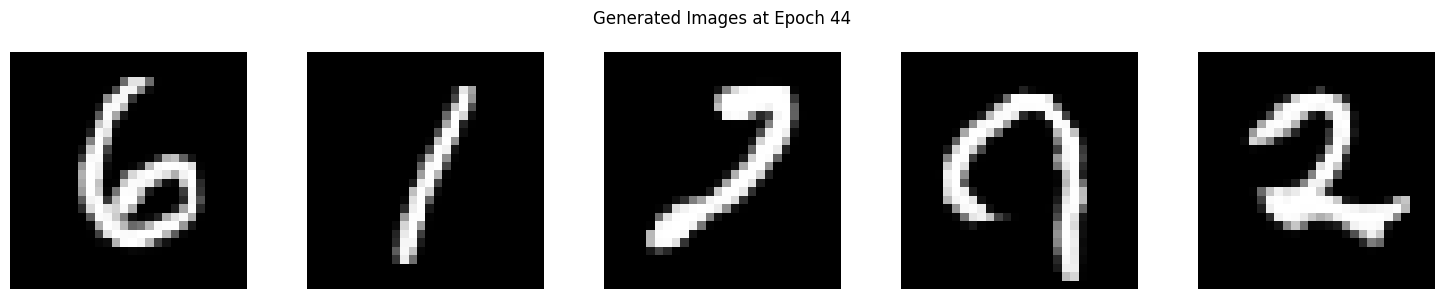

Epoch [45/50], Batch [0/469], D Loss: 0.6617, G Loss: 2.4109
Epoch [45/50], Batch [100/469], D Loss: 0.7050, G Loss: 1.8254
Epoch [45/50], Batch [200/469], D Loss: 1.0511, G Loss: 2.0141
Epoch [45/50], Batch [300/469], D Loss: 0.5859, G Loss: 2.0623
Epoch [45/50], Batch [400/469], D Loss: 0.7769, G Loss: 1.5664
Epoch [45/50] complete. Avg D Loss: 0.6893, Avg G Loss: 2.4251


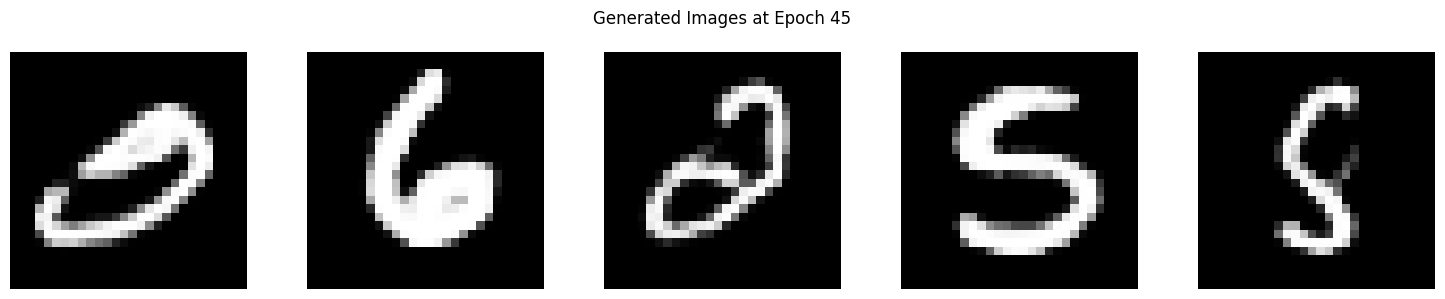

Epoch [46/50], Batch [0/469], D Loss: 0.7401, G Loss: 2.9944
Epoch [46/50], Batch [100/469], D Loss: 0.5861, G Loss: 2.7262
Epoch [46/50], Batch [200/469], D Loss: 0.6085, G Loss: 1.3462
Epoch [46/50], Batch [300/469], D Loss: 0.7712, G Loss: 2.4569
Epoch [46/50], Batch [400/469], D Loss: 0.8226, G Loss: 2.0823
Epoch [46/50] complete. Avg D Loss: 0.6592, Avg G Loss: 2.3503


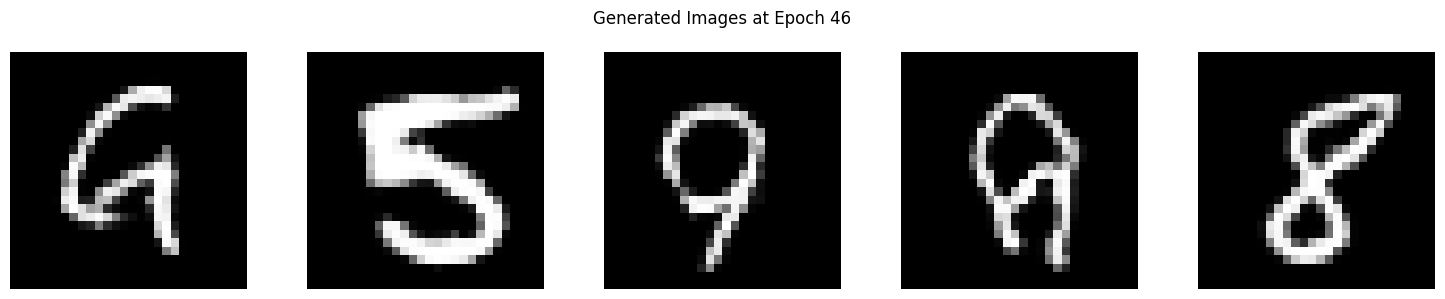

Epoch [47/50], Batch [0/469], D Loss: 0.5166, G Loss: 2.5281
Epoch [47/50], Batch [100/469], D Loss: 0.6540, G Loss: 2.0123
Epoch [47/50], Batch [200/469], D Loss: 0.8120, G Loss: 3.5172
Epoch [47/50], Batch [300/469], D Loss: 0.9392, G Loss: 1.7716
Epoch [47/50], Batch [400/469], D Loss: 0.6913, G Loss: 2.9067
Epoch [47/50] complete. Avg D Loss: 0.6937, Avg G Loss: 2.4109


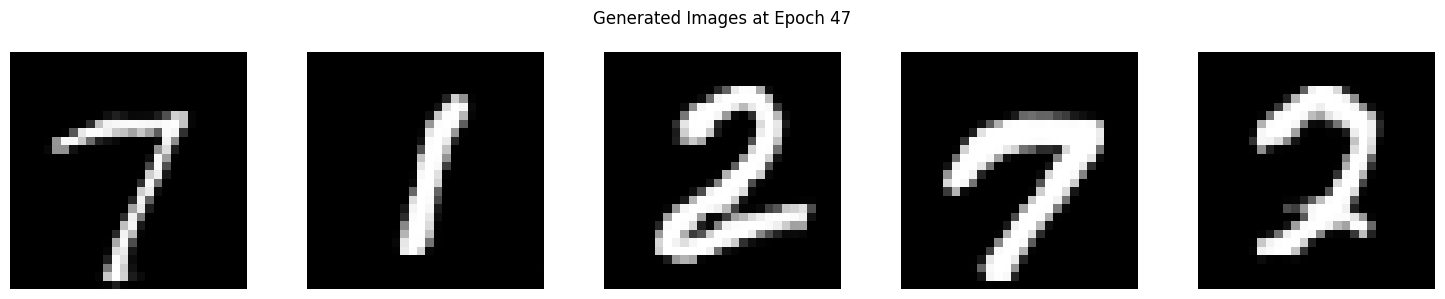

Epoch [48/50], Batch [0/469], D Loss: 0.9289, G Loss: 2.6420
Epoch [48/50], Batch [100/469], D Loss: 0.6066, G Loss: 2.3113
Epoch [48/50], Batch [200/469], D Loss: 0.7322, G Loss: 2.0826
Epoch [48/50], Batch [300/469], D Loss: 0.5997, G Loss: 1.9339
Epoch [48/50], Batch [400/469], D Loss: 0.5821, G Loss: 2.7121
Epoch [48/50] complete. Avg D Loss: 0.6538, Avg G Loss: 2.3801


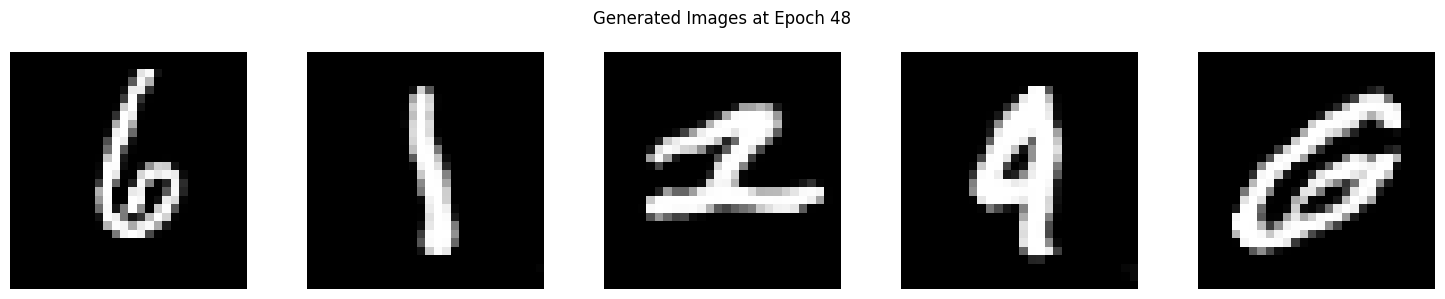

Epoch [49/50], Batch [0/469], D Loss: 0.8713, G Loss: 3.0637
Epoch [49/50], Batch [100/469], D Loss: 0.4837, G Loss: 1.0644
Epoch [49/50], Batch [200/469], D Loss: 0.5810, G Loss: 1.8943
Epoch [49/50], Batch [300/469], D Loss: 0.6446, G Loss: 2.1385
Epoch [49/50], Batch [400/469], D Loss: 1.0324, G Loss: 2.1528
Epoch [49/50] complete. Avg D Loss: 0.6608, Avg G Loss: 2.3764


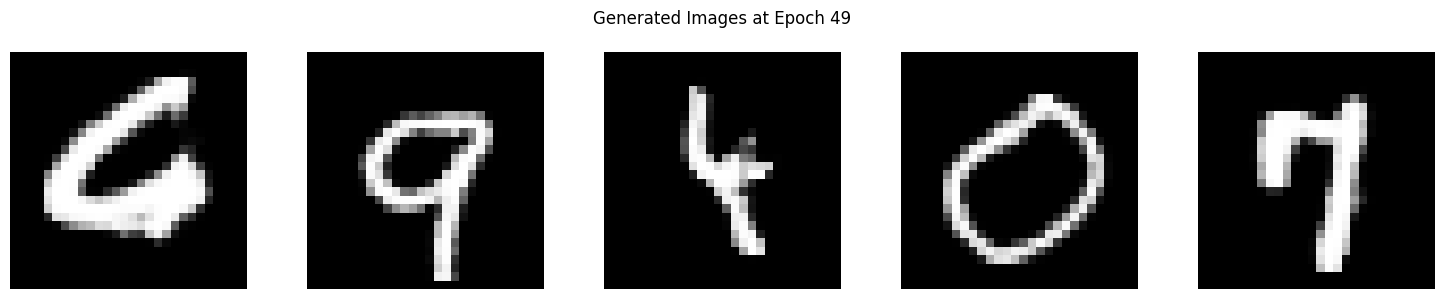

Epoch [50/50], Batch [0/469], D Loss: 0.6057, G Loss: 1.7916
Epoch [50/50], Batch [100/469], D Loss: 0.5953, G Loss: 1.4237
Epoch [50/50], Batch [200/469], D Loss: 0.5921, G Loss: 2.6809
Epoch [50/50], Batch [300/469], D Loss: 0.5215, G Loss: 2.4288
Epoch [50/50], Batch [400/469], D Loss: 0.6554, G Loss: 1.7398
Epoch [50/50] complete. Avg D Loss: 0.6718, Avg G Loss: 2.4673


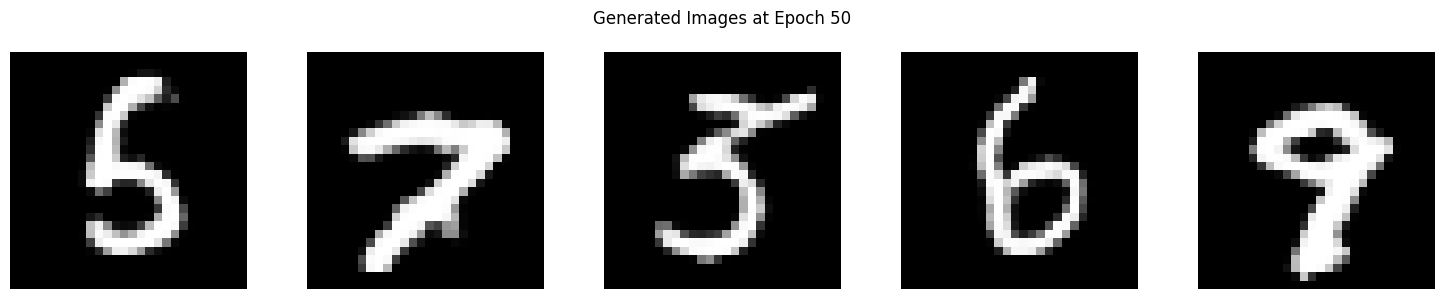

Saved


In [24]:
epochs = 50

def generator_loss_non_saturating(d_fake):
    return -torch.mean(torch.log(d_fake + 1e-8))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator.to(device)
discriminator.to(device)

epoch_g_losses = []
epoch_d_losses = []
best_gen_loss = float('inf')
best_generator_state = None
best_discriminator_state = None

for epoch in range(epochs):
    generator.train()
    discriminator.train()
    total_g_loss = 0.0
    total_d_loss = 0.0
    num_batches = 0
    d_batch_count = 0

    for batch_idx, (real_images, _) in enumerate(train_loader):
        current_batch_size = real_images.size(0)
        real_images = real_images.to(device)

        optimizer_d.zero_grad()
        real_labels = torch.full((current_batch_size, 1), 0.9, device=device)
        fake_labels = torch.zeros(current_batch_size, 1, device=device)
        real_outputs = discriminator(real_images)
        d_loss_real = criterion(real_outputs, real_labels)
        noise = torch.randn(current_batch_size, 50, device=device)
        fake_images = generator(noise).detach()
        d_fake_outputs = discriminator(fake_images)
        d_loss_fake = criterion(d_fake_outputs, fake_labels)
        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        optimizer_d.step()
        total_d_loss += d_loss.item()
        d_batch_count += 1

        optimizer_g.zero_grad()
        noise = torch.randn(current_batch_size, 50, device=device)
        gen_imgs = generator(noise)
        d_gen_outputs = discriminator(gen_imgs)
        g_loss = generator_loss_non_saturating(d_gen_outputs)
        g_loss.backward()
        optimizer_g.step()
        total_g_loss += g_loss.item()
        num_batches += 1
        if batch_idx % 100 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], Batch [{batch_idx}/{len(train_loader)}], D Loss: {d_loss.item():.4f}, G Loss: {g_loss.item():.4f}")

    avg_d_loss = total_d_loss / d_batch_count if d_batch_count > 0 else 0.0
    avg_g_loss = total_g_loss / num_batches
    epoch_d_losses.append(avg_d_loss)
    epoch_g_losses.append(avg_g_loss)
    print(f"Epoch [{epoch+1}/{epochs}] complete. Avg D Loss: {avg_d_loss:.4f}, Avg G Loss: {avg_g_loss:.4f}")
    if avg_g_loss < best_gen_loss:
        best_gen_loss = avg_g_loss
        best_generator_state = generator.state_dict()
        best_discriminator_state = discriminator.state_dict()
    generator.eval()
    with torch.no_grad():
        sample_noise = torch.randn(5, 50, device=device)
        generated_samples = generator(sample_noise).cpu().numpy()
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))
    for idx, ax in enumerate(axes):
        ax.imshow(generated_samples[idx][0], cmap='gray')
        ax.axis('off')
    plt.suptitle(f"Generated Images at Epoch {epoch+1}")
    plt.tight_layout()
    plt.show()

torch.save(best_generator_state, 'mnist_generator.pth')
torch.save(best_discriminator_state, 'mnist_discriminator.pth')
print("Saved")


## Loss curves and generated digits

Plot the training history and display 25 samples from the saved generator.

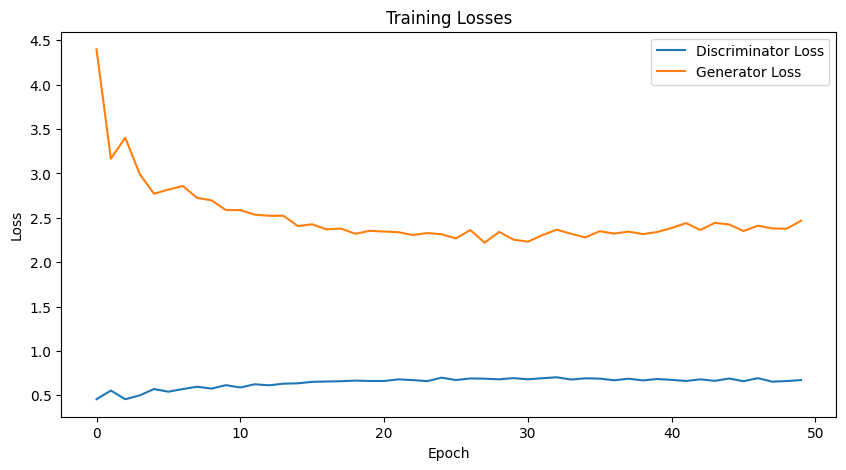

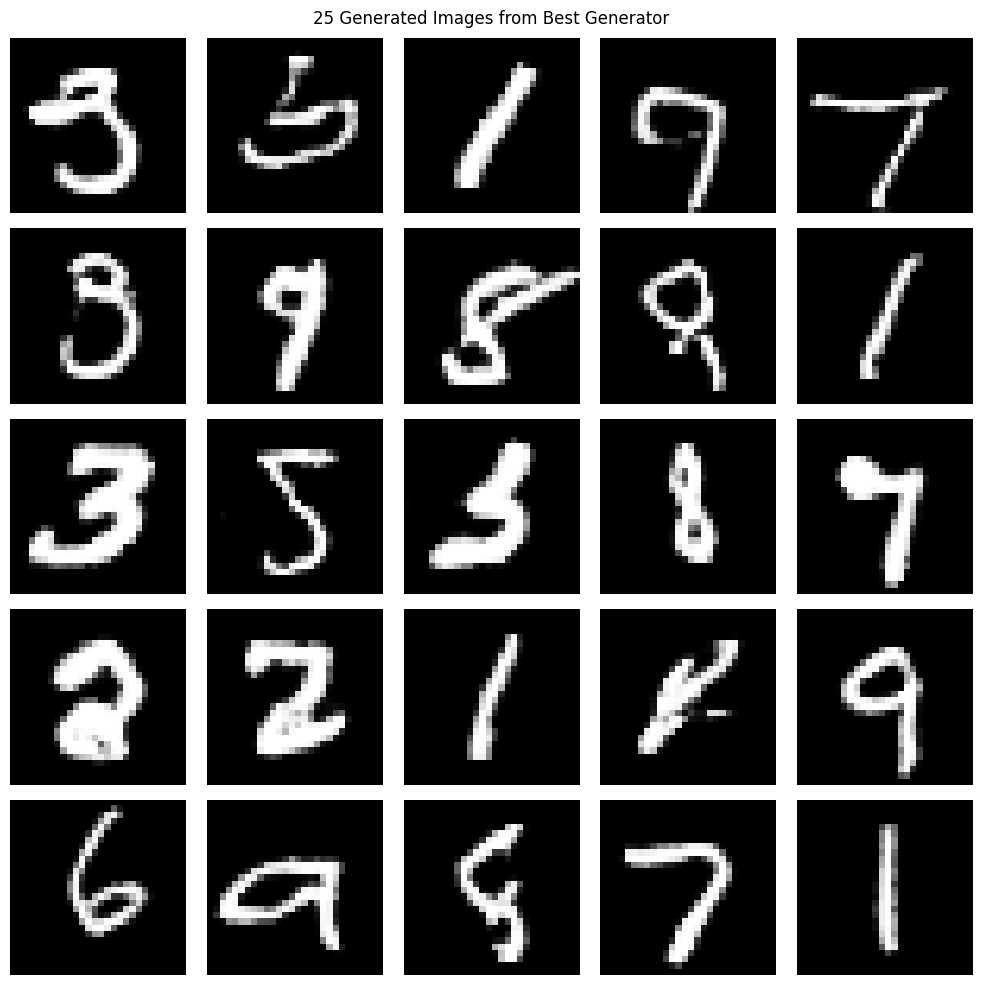

In [29]:
plt.figure(figsize=(10, 5))
plt.plot(epoch_d_losses, label='Discriminator Loss')
plt.plot(epoch_g_losses, label='Generator Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Losses')
plt.legend()
plt.show()

generator.load_state_dict(torch.load('mnist_generator.pth', map_location=device))
generator.eval()
generator.to(device)
with torch.no_grad():
    sample_noise = torch.randn(25, 50, device=device)
    generated_images = generator(sample_noise).cpu().numpy()

fig, axes = plt.subplots(5, 5, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i, 0], cmap='gray')
    ax.axis('off')
plt.suptitle("25 Generated Images from Best Generator")
plt.tight_layout()
plt.show()


## MNIST latent interpolation

Generate a sequence of images along a linear path between two random latent vectors:

$$z(\alpha)=\alpha z_1+(1-\alpha)z_2,\qquad \alpha\in[0,1].$$

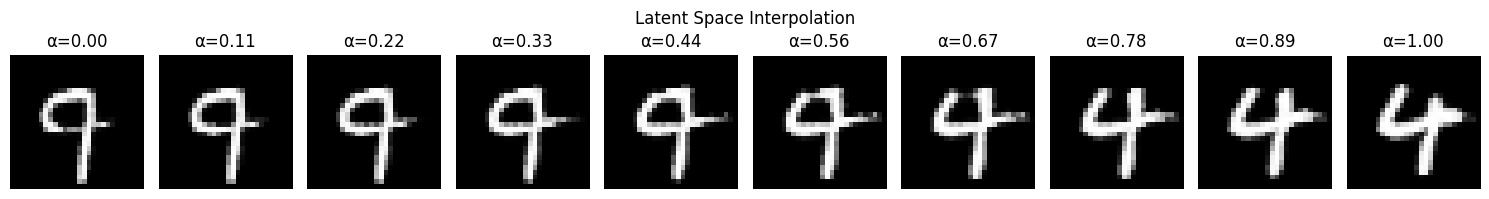

In [33]:
noise_latent1 = torch.randn(1,50).to(device)
noise_latent2 = torch.randn(1,50).to(device)

interpolated_latents = []
alphas = torch.linspace(0, 1, steps=10).to(device)
for alpha in alphas:
    z_interp = alpha * noise_latent1 + (1 - alpha) * noise_latent2
    interpolated_latents.append(z_interp)

interpolated_latents = torch.cat(interpolated_latents, dim = 0)
with torch.no_grad():
    interpolated_images = generator(interpolated_latents).cpu().numpy()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(interpolated_images[i, 0], cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(f'α={alphas[i]:.2f}')
plt.suptitle("Latent Space Interpolation")
plt.tight_layout()
plt.show()


## Pretrained CelebA generator

Load the pretrained face generator. Place the compatible `dcgan.py` wrapper and `generator.pt` checkpoint beside this notebook.


In [34]:
from dcgan import DCGAN
generator_path = "generator.pt"
gan = DCGAN(gan_type="gan", use_cuda=True)
gan.load_model(filename=generator_path, use_cuda=torch.cuda.is_available())
gan.eval()
gan = gan.to(device)
print("Number of parameters in the pre-trained generator:", gan.get_num_params())


Loading generator checkpoint from: generator.pt
Number of parameters in the pre-trained generator: 3592064


## Face interpolation

Visualize the endpoint images and generate an 11-step transition between their latent vectors.

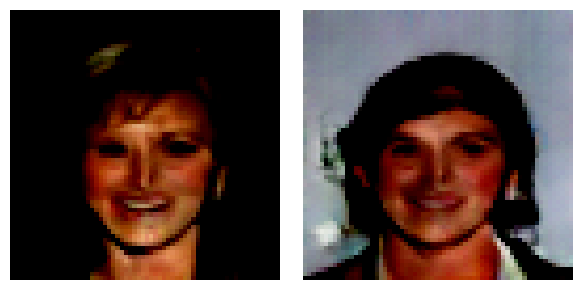

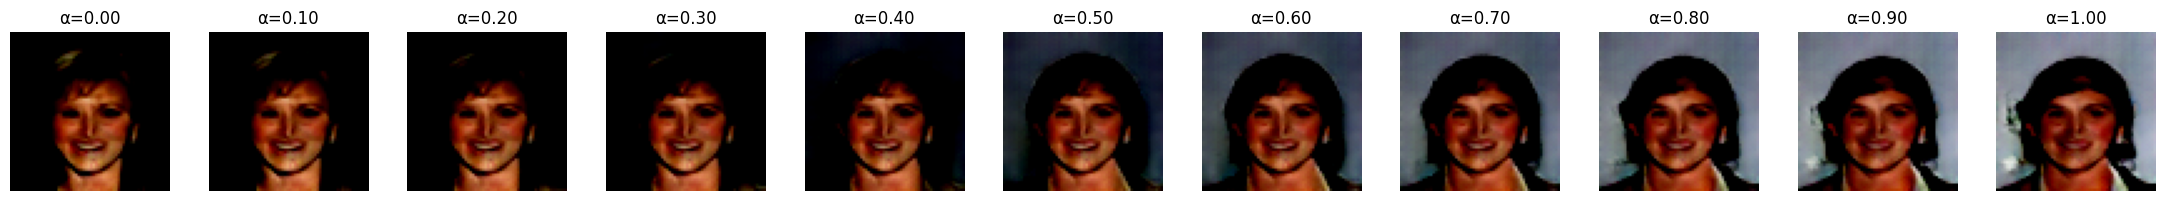

In [111]:
noise_latent1 = torch.randn(1, 100).to(device)
noise_latent2 = torch.randn(1, 100).to(device)

with torch.no_grad():
    img1 = gan.G(noise_latent1).cpu()
    img1 = torch.clamp(img1, 0, 1)
    img2 = gan.G(noise_latent2).cpu()
    img2 = torch.clamp(img2, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(img2[0].permute(1, 2, 0).numpy())
axes[0].axis('off')
axes[1].imshow(img1[0].permute(1, 2, 0).numpy())
axes[1].axis('off')
plt.tight_layout()
plt.show()

alphas = torch.linspace(0, 1, steps=11).to(device)
interpolated_latents = [(alpha * noise_latent1 + (1 - alpha) * noise_latent2) for alpha in alphas]
interpolated_latents = torch.cat(interpolated_latents, dim=0)

with torch.no_grad():
    interpolated_images = gan.G(interpolated_latents).cpu()
    interpolated_images = torch.clamp(interpolated_images, 0, 1)

fig, axes = plt.subplots(1, 11, figsize=(22, 2))
for i in range(11):
    axes[i].imshow(interpolated_images[i].permute(1, 2, 0).numpy())
    axes[i].axis('off')
    axes[i].set_title(f'α={alphas[i]:.2f}')
plt.tight_layout()
plt.show()


## Latent vector arithmetic

Explore how subtraction, three-vector combinations, and averaging change generated images.

### Vector difference

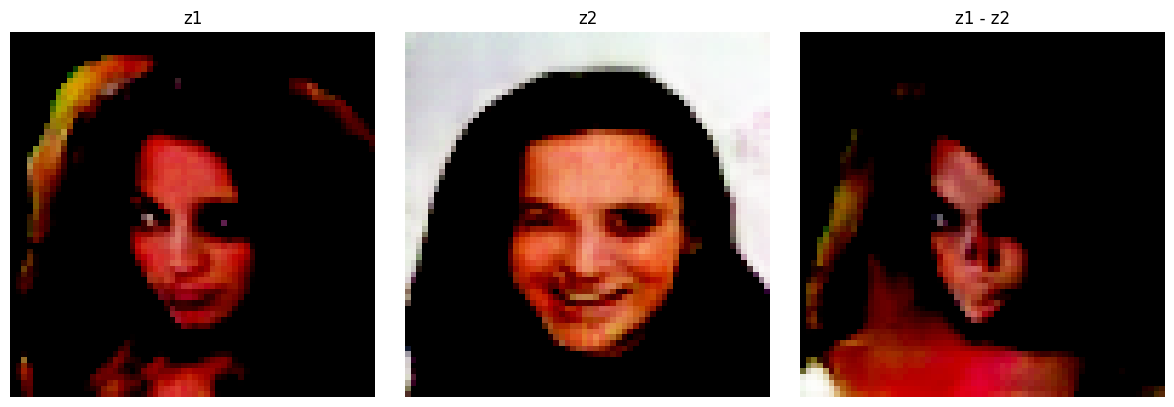

In [132]:
noise_latent1 = torch.randn(1, 100).to(device)
noise_latent2 = torch.randn(1, 100).to(device)

img_noise_latent1 = gan.G(noise_latent1).detach().cpu()
img_noise_latent1 = torch.clamp(img_noise_latent1, 0, 1)
img_noise_latent2 = gan.G(noise_latent2).detach().cpu()
img_noise_latent2 = torch.clamp(img_noise_latent2, 0, 1)
img_add = gan.G(noise_latent1 - noise_latent2).detach().cpu()
img_add = torch.clamp(img_add, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_noise_latent1[0].permute(1, 2, 0).numpy())
axes[0].set_title("z1")
axes[0].axis('off')
axes[1].imshow(img_noise_latent2[0].permute(1, 2, 0).numpy())
axes[1].set_title("z2")
axes[1].axis('off')
axes[2].imshow(img_add[0].permute(1, 2, 0).numpy())
axes[2].set_title("z1 - z2")
axes[2].axis('off')
plt.tight_layout()
plt.show()


### Three-vector combination

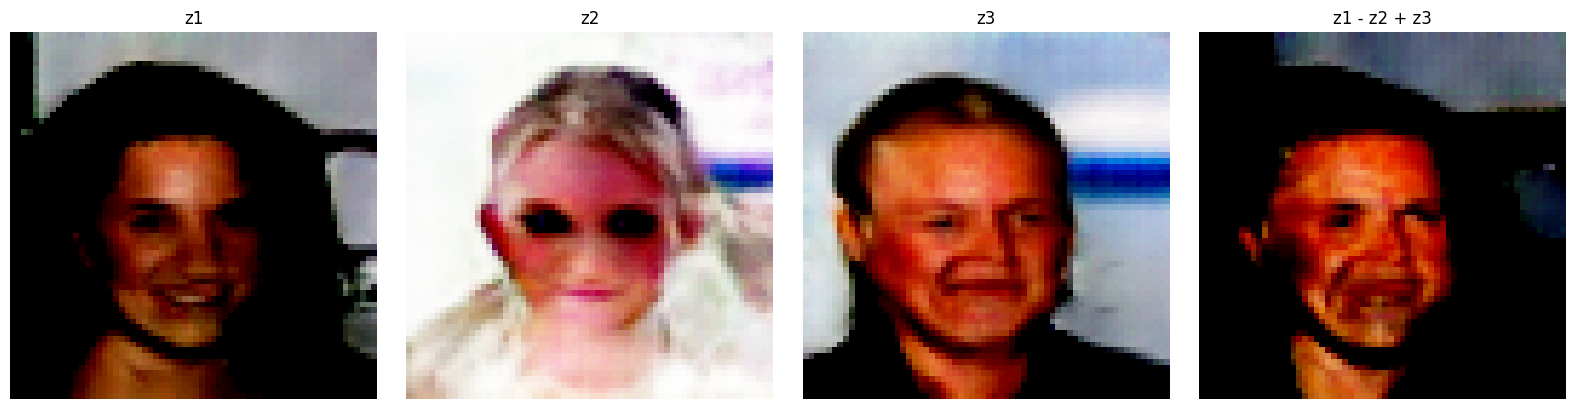

In [108]:
noise_latent1 = torch.randn(1, 100).to(device)
noise_latent2 = torch.randn(1, 100).to(device)
noise_latent3 = torch.randn(1, 100).to(device)

img_noise_latent1 = gan.G(noise_latent1).detach().cpu()
img_noise_latent1 = torch.clamp(img_noise_latent1, 0, 1)
img_noise_latent2 = gan.G(noise_latent2).detach().cpu()
img_noise_latent2 = torch.clamp(img_noise_latent2, 0, 1)
img_noise_latent3 = gan.G(noise_latent3).detach().cpu()
img_noise_latent3 = torch.clamp(img_noise_latent3, 0, 1)
img_subadd = gan.G(noise_latent1 - noise_latent2 + noise_latent3).detach().cpu()
img_subadd = torch.clamp(img_subadd, 0, 1)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_noise_latent1[0].permute(1, 2, 0).numpy())
axes[0].set_title("z1")
axes[0].axis('off')
axes[1].imshow(img_noise_latent2[0].permute(1, 2, 0).numpy())
axes[1].set_title("z2")
axes[1].axis('off')
axes[2].imshow(img_noise_latent3[0].permute(1, 2, 0).numpy())
axes[2].set_title("z3")
axes[2].axis('off')
axes[3].imshow(img_subadd[0].permute(1, 2, 0).numpy())
axes[3].set_title("z1 - z2 + z3")
axes[3].axis('off')
plt.tight_layout()
plt.show()


### Latent average

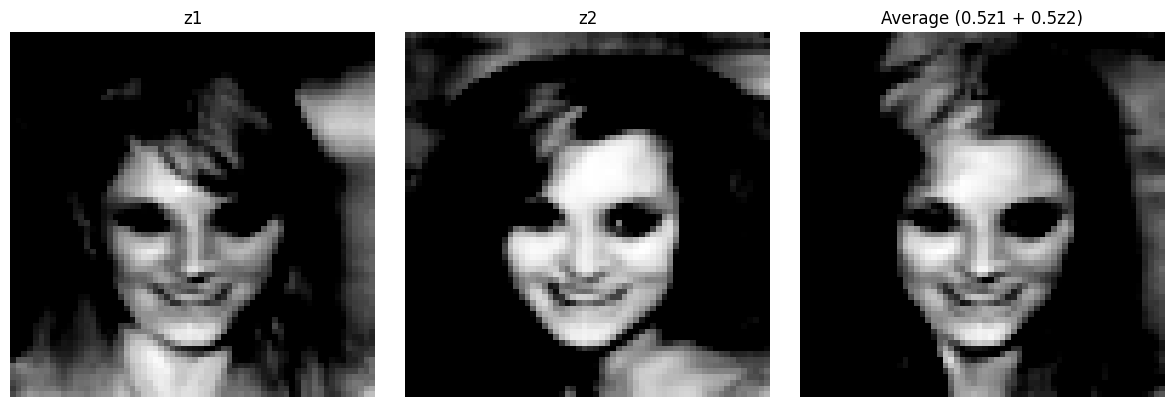

In [109]:
noise_latent1 = torch.randn(1, 100).to(device)
noise_latent2 = torch.randn(1, 100).to(device)

img_noise_latent1 = gan.G(noise_latent1).detach().cpu()
img_noise_latent1 = torch.clamp(img_noise_latent1, 0, 1)
img_noise_latent2 = gan.G(noise_latent2).detach().cpu()
img_noise_latent2 = torch.clamp(img_noise_latent2, 0, 1)
img_avg = gan.G(0.5 * noise_latent1 + 0.5 * noise_latent2).detach().cpu()
img_avg = torch.clamp(img_avg, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_noise_latent1[0, 0].detach().numpy(), cmap='gray')
axes[0].set_title("z1")
axes[0].axis('off')
axes[1].imshow(img_noise_latent2[0, 0].detach().numpy(), cmap='gray')
axes[1].set_title("z2")
axes[1].axis('off')
axes[2].imshow(img_avg[0, 0].detach().numpy(), cmap='gray')
axes[2].set_title("Average (0.5z1 + 0.5z2)")
axes[2].axis('off')
plt.tight_layout()
plt.show()
